<a href="https://colab.research.google.com/github/usumakikai8-bot/DNN4/blob/main/dnn6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook audit and constraint implementation notes

- The input has 67 features. Raw index 2 is applied load, indices 4–13 are ordered X-span lengths, and indices 14–23 are ordered Y-span lengths. Active counts are raw indices 0 and 1.
- The model predicts categorical catalog scores for each beam and column slot. H-section height is catalog dimension index 0; constraints use its differentiable softmax expectation.
- Pair matching requires equal floor count, X/Y span counts, cumulative floor heights, and corresponding beam slot. Active X/Y spans are aligned by ordinal position; padded values are ignored. Load and all active span lengths must be componentwise greater than or equal in the larger sample, with at least one strict inequality.
- Pair generation is independent per split. Section labels and steel-weight outcomes are excluded from structural matching because they are targets/outcomes.
- USE_LAGRANGIAN_CONSTRAINTS switches between constrained and baseline training. Each mode has separate checkpoint and history files. The architecture and supervised loss remain unchanged.

## Training-data / catalog alignment

- Training files are parsed by content (`建物条件`, `スパン割`, `階高`, `柱断面リスト`, `梁断面リスト`), not by file name. Floors, X/Y span counts and load come from the `建物条件` table; the building id comes from the first line (e.g. `0001`).
- Beam catalog: `JIS_SN_medium_narrow_H_list_DNN.csv`. Only rows with `enabled == 1` are candidates. Dimensions are `nominal_H_mm, nominal_B_mm, tw_mm, tf_mm` (index 0 is still the nominal H used by the monotonicity constraint).
- Column catalog: `BCR_square_tube_list_DNN.csv` (`D_mm, t_mm`). Column names in training files use `□-` (e.g. `□-150x150x6x15`); this is mapped to the catalog prefix `B-`.


# Optional Lagrangian monotonicity constraints

Set `USE_LAGRANGIAN_CONSTRAINTS` to `False` for the unconstrained baseline.

## Imports and configuration

In [ ]:

import csv
import hashlib
import json
import random
import re
from collections import Counter
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

%cd /content/drive/MyDrive/research/DNN6


/content/drive/MyDrive/research/DNN6


In [ ]:
%pwd

'/content/drive/MyDrive/research/DNN6'

Use paths that match the current project and dataset environment.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path
PROJECT_ROOT = Path.cwd()

DATASET_ROOT = Path(r'/content/drive/MyDrive/research/dataset-dnn6') if Path(r'/content/drive/MyDrive/research/dataset-dnn6').exists() else Path('/content/drive/MyDrive/research/dataset-dnn6')
CATALOG_ROOT = DATASET_ROOT / 'dnn-catalog-1107'
H_CATALOG_FILE = 'JIS_SN_medium_narrow_H_list_DNN.csv'
BOX_CATALOG_FILE = 'BCR_square_tube_list_DNN.csv'
OUTPUT_DIR = PROJECT_ROOT / 'dnn_result'
print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATASET_ROOT:', DATASET_ROOT)
print('CATALOG_ROOT:', CATALOG_ROOT)
print('H catalog file:', H_CATALOG_FILE, '/ box catalog file:', BOX_CATALOG_FILE)
print('OUTPUT_DIR:', OUTPUT_DIR)

PROJECT_ROOT: /content/drive/My Drive/research/DNN6
DATASET_ROOT: /content/drive/MyDrive/research/dataset-dnn6
CATALOG_ROOT: /content/drive/MyDrive/research/dataset-dnn6/dnn-catalog-1107
H catalog file: JIS_SN_medium_narrow_H_list_DNN.csv / box catalog file: BCR_square_tube_list_DNN.csv
OUTPUT_DIR: /content/drive/My Drive/research/DNN6/dnn_result


In [ ]:
SEED = 42
BATCH_SIZE = 256
EPOCHS = 400
PATIENCE = 35
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 1e-4
MAX_SPANS = 10
MIN_SPAN_MM = 4000.0
MAX_SPAN_MM_NORMALIZATION = 12000.0
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#Set USE_LAGRANGIAN_CONSTRAINTS to False for the unconstrained baseline.
USE_LAGRANGIAN_CONSTRAINTS = True
LAGRANGE_LR = 1e-2
CONSTRAINT_BATCH_SIZE = 128
CONSTRAINT_EVAL_BATCH_SIZE = 2048
CHECKPOINT_PATH = OUTPUT_DIR / ("best_section_dnn_lagrangian.pt" if USE_LAGRANGIAN_CONSTRAINTS else "best_section_dnn_baseline.pt")
PREDICTIONS_PATH = OUTPUT_DIR / ("test_catalog_predictions_lagrangian.csv" if USE_LAGRANGIAN_CONSTRAINTS else "test_catalog_predictions_baseline.csv")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'{DEVICE=}')
missing = [str(DATASET_ROOT / s) for s in ('train', 'val', 'test') if not (DATASET_ROOT / s).is_dir()]
if missing: raise FileNotFoundError(f'train/val/test が見つかりません: {missing}')
if not CATALOG_ROOT.is_dir():
    raise FileNotFoundError(f'カタログCSVのフォルダがありません: {CATALOG_ROOT}。{H_CATALOG_FILE} と {BOX_CATALOG_FILE} を配置してください。')
missing_catalogs = [str(CATALOG_ROOT / f) for f in (H_CATALOG_FILE, BOX_CATALOG_FILE) if not (CATALOG_ROOT / f).is_file()]
if missing_catalogs: raise FileNotFoundError(f'カタログCSVがありません: {missing_catalogs}')

LOSS_MODE = 'dimension_mse'  # 'cross_entropy' and 'combined' are also available
LAMBDA_DIM = 0.1
SECTION_WEIGHT_H = 1.0
SECTION_WEIGHT_BOX = 2.0


TRAINING_HISTORY_PATH = OUTPUT_DIR / f"training_history_{'lagrangian' if USE_LAGRANGIAN_CONSTRAINTS else 'baseline'}.csv"


DEVICE=device(type='cuda')


## Data loading and preprocessing

In [ ]:
def seed_everything(seed: int = SEED) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def read_text(path: Path) -> str:
    for encoding in ('utf-8-sig', 'utf-8', 'cp932'):
        try: return path.read_text(encoding=encoding)
        except UnicodeDecodeError: pass
    return path.read_text(encoding='utf-8', errors='replace')

def read_catalog(path: Path, kind: str) -> list[dict]:
    rows = list(csv.DictReader(read_text(path).splitlines()))
    name_col = 'name'
    cols = ('nominal_H_mm', 'nominal_B_mm', 'tw_mm', 'tf_mm') if kind == 'h' else ('D_mm', 't_mm')
    required = {name_col, *cols, *(('enabled',) if kind == 'h' else ())}
    if not rows or not required.issubset(rows[0]):
        raise ValueError(f'カタログCSVの列が想定と異なります: {path}')
    if kind == 'h':  # only sections flagged enabled=1 are DNN candidates
        rows = [r for r in rows if r['enabled'].strip() == '1']
    catalog = [{'name': r[name_col].strip(), 'values': tuple(float(r[c]) for c in cols)} for r in rows]
    if len({r['name'] for r in catalog}) != len(catalog): raise ValueError(f'カタログ内に断面名の重複があります: {path}')
    return catalog

H_CATALOG = read_catalog(CATALOG_ROOT / H_CATALOG_FILE, 'h')
BOX_CATALOG = read_catalog(CATALOG_ROOT / BOX_CATALOG_FILE, 'box')
print(f'H catalog: {len(H_CATALOG)}, box catalog: {len(BOX_CATALOG)}')


H catalog: 23, box catalog: 58


## Feature preparation

# Load is normalized to the configured range (0, 10).

In [ ]:
def table_after_marker(text, marker):
    lines=text.splitlines(); start=next(i for i,line in enumerate(lines) if line.strip()==marker)
    data_at=next(i for i in range(start+1,len(lines)) if lines[i].strip()=='<data>')
    header=next(csv.reader([lines[data_at-1]])); rows=[]
    for line in lines[data_at+1:]:
        if not line.strip() or line.strip().startswith('name='): break
        rows.append(next(csv.reader([line])))
    return header,rows

def nominal_to_catalog_name(nominal, kind):
    name=nominal.strip(); cat=H_CATALOG if kind=='h' else BOX_CATALOG
    if kind=='box': name=re.sub(r'^[□■]\s*-?\s*','B-',name)  # training files: □-150x150x6x15 -> catalog: B-150x150x6x15
    if name not in {r['name'] for r in cat}: raise ValueError(f'カタログにない断面名: {name}')
    return name

def parse_targets(path):
    text=read_text(path); out={}; header,rows=table_after_marker(text,'name=柱断面リスト')
    for row in rows:
        for symbol,section in zip(header[1:],row[1:]):
            if section.strip(): out[f'column:{row[0].strip()}:{symbol.strip()}']=('box',nominal_to_catalog_name(section,'box'))
    header,rows=table_after_marker(text,'name=梁断面リスト')
    for row in rows:
        for symbol,section in zip(header[1:],row[1:]):
            if section.strip(): out[f'beam:{row[0].strip()}:{symbol.strip()}']=('h',nominal_to_catalog_name(section,'h'))
    return out

def parse_building_conditions(text, path):
    """Read floors / X,Y span counts / load from the 建物条件 table and the building id from line 1."""
    header,rows=table_after_marker(text,'name=建物条件')
    if not rows: raise ValueError(f'建物条件がありません: {path}')
    col=lambda key: next(i for i,h in enumerate(header) if h.strip().startswith(key)); r=rows[0]
    first=next(csv.reader([text.lstrip('\ufeff').splitlines()[0]]))
    building_id=first[1].strip() if len(first)>1 and first[1].strip() else Path(path).stem
    return {'building_id':building_id,'floors':int(float(r[col('階数')])),'nx':int(float(r[col('Xスパン数')])),
            'ny':int(float(r[col('Yスパン数')])),'load':float(r[col('鉛直面荷重')])}

def features_from_file(path):
    text=read_text(path); cond=parse_building_conditions(text,path)
    nx,ny,floors,load=cond['nx'],cond['ny'],cond['floors'],cond['load']
    sh,srows=table_after_marker(text,'name=スパン割'); sc=[i for i,h in enumerate(sh) if h.startswith('スパン')]
    sp={r[0].strip():[float(r[i]) for i in sc if i<len(r) and r[i].strip()] for r in srows}; sx,sy=sp['X'],sp['Y']
    if len(sx)!=nx or len(sy)!=ny: raise ValueError(f'スパン数不一致: {path.name}')
    if max(nx,ny,floors)>MAX_SPANS: raise ValueError(f'MAX_SPANS超過: {path.name}')
    if min(sx+sy)<MIN_SPAN_MM: raise ValueError(f'最小スパン未満: {path.name}')
    xl=sx+[0.]*(MAX_SPANS-nx); yl=sy+[0.]*(MAX_SPANS-ny); xm=[1.]*nx+[0.]*(MAX_SPANS-nx); ym=[1.]*ny+[0.]*(MAX_SPANS-ny)
    hh,hr=table_after_marker(text,'name=階高'); hi=next(i for i,h in enumerate(hh) if '階高' in h); hd={r[0].strip():float(r[hi]) for r in hr if len(r)>hi and r[hi].strip()}
    z=[]; acc=0.
    for f in range(1,floors+1):
        acc+=hd[f'{f}FL']; z.append(acc)
    zm=[1.]*floors+[0.]*(MAX_SPANS-floors); z += [0.]*(MAX_SPANS-floors)
    return np.asarray([nx,ny,load,floors,*xl,*yl,*xm,*ym,*z,*zm,float(nx>0),float(ny>0),float(floors>0)],dtype=np.float32)

@dataclass
class Sample:
    file_name: str
    x: np.ndarray
    targets: dict
    meta: dict = None

def load_split(split):
    paths=sorted((DATASET_ROOT/split).glob('*.csv'))
    samples=[Sample(p.name,features_from_file(p),parse_targets(p),parse_building_conditions(read_text(p),p)) for p in paths]
    print(f'{split}: {len(samples)} files'); return samples

seed_everything()
train_samples,val_samples,test_samples=(load_split(s) for s in ('train','val','test'))
SLOTS=sorted({k for sm in train_samples for k in sm.targets})
SLOT_TYPES=[next(sm.targets[k][0] for sm in train_samples if k in sm.targets) for k in SLOTS]
H_TO_ID={r['name']:i for i,r in enumerate(H_CATALOG)}; BOX_TO_ID={r['name']:i for i,r in enumerate(BOX_CATALOG)}
FEATURE_NORMALIZATION=[(1,10),(1,10),(0,10),(1,10)]+[(MIN_SPAN_MM,MAX_SPAN_MM_NORMALIZATION)]*(2*MAX_SPANS)+[(0,1)]*(2*MAX_SPANS)+[(0,40000)]*MAX_SPANS+[(0,1)]*MAX_SPANS+[(0,1)]*3
feature_min=np.asarray([a for a,b in FEATURE_NORMALIZATION],dtype=np.float32); feature_max=np.asarray([b for a,b in FEATURE_NORMALIZATION],dtype=np.float32); feature_range=feature_max-feature_min
FEATURE_NAMES = ['nx','ny','load','floors'] + [f'x_span_{i+1}' for i in range(MAX_SPANS)] + [f'y_span_{i+1}' for i in range(MAX_SPANS)] + [f'x_valid_{i+1}' for i in range(MAX_SPANS)] + [f'y_valid_{i+1}' for i in range(MAX_SPANS)] + [f'cumulative_height_{i+1}' for i in range(MAX_SPANS)] + [f'height_valid_{i+1}' for i in range(MAX_SPANS)] + ['has_x','has_y','has_floors']
if len(FEATURE_NAMES) != len(FEATURE_NORMALIZATION):
    raise ValueError(f'feature name/normalization mismatch: {len(FEATURE_NAMES)} vs {len(FEATURE_NORMALIZATION)}')
class SectionDataset(Dataset):
    def __init__(self,samples): self.samples=samples
    def __len__(self): return len(self.samples)
    def __getitem__(self,i):
        sm=self.samples[i]; yh=[]; yb=[]
        for slot,kind in zip(SLOTS,SLOT_TYPES):
            arr=yh if kind=='h' else yb
            if slot not in sm.targets: arr.append(-100)
            else:
                _,name=sm.targets[slot]; arr.append((H_TO_ID if kind=='h' else BOX_TO_ID)[name])
        x=np.clip((sm.x-feature_min)/feature_range,0,1); x[24:34]*=x[64]
        x[34:44]*=x[65]
        x[44:54]*=x[54:64]
        return torch.tensor(x,dtype=torch.float32),torch.tensor(yh,dtype=torch.long),torch.tensor(yb,dtype=torch.long),sm.file_name
train_dataset=SectionDataset(train_samples)
train_loader=DataLoader(train_dataset,batch_size=BATCH_SIZE,shuffle=True)
val_dataset=SectionDataset(val_samples); test_dataset=SectionDataset(test_samples)
val_loader=DataLoader(val_dataset,batch_size=BATCH_SIZE); test_loader=DataLoader(test_dataset,batch_size=BATCH_SIZE)
N_H_SLOTS=sum(k=='h' for k in SLOT_TYPES); N_BOX_SLOTS=sum(k=='box' for k in SLOT_TYPES)
print(f'入力特徴量={len(FEATURE_NORMALIZATION)} (X/Yスパン・有効マスク・z高さ・z有効マスク), 梁slot={N_H_SLOTS}, 柱slot={N_BOX_SLOTS}')



LOAD_INDEX = 2
X_SPAN_START, Y_SPAN_START = 4, 14
FLOOR_HEIGHT_START = 44

def structural_pair_key(sample):
    """Match non-varied structural inputs represented by the model."""
    x = np.asarray(sample.x)
    nx, ny, floors = int(round(x[0])), int(round(x[1])), int(round(x[3]))
    heights = tuple(float(v) for v in x[FLOOR_HEIGHT_START:FLOOR_HEIGHT_START + floors])
    return nx, ny, floors, heights

def generate_constraint_pairs(samples):
    """Return unique oriented (larger_index, smaller_index, H_slot_index) triples."""
    from itertools import combinations
    from collections import defaultdict
    groups = defaultdict(list)
    for index, sample in enumerate(samples):
        base_key = structural_pair_key(sample)
        for slot, (kind, _) in sample.targets.items():
            if kind == 'h':
                groups[(base_key, slot)].append(index)
    pairs, seen = [], set()
    for (_, slot), indices in groups.items():
        global_slot = SLOTS.index(slot)
        h_slot = sum(kind == 'h' for kind in SLOT_TYPES[:global_slot])
        for a, b in combinations(indices, 2):
            xa, xb = np.asarray(samples[a].x), np.asarray(samples[b].x)
            nx, ny = int(round(xa[0])), int(round(xa[1]))
            va = np.concatenate((xa[X_SPAN_START:X_SPAN_START+nx], xa[Y_SPAN_START:Y_SPAN_START+ny], xa[LOAD_INDEX:LOAD_INDEX+1]))
            vb = np.concatenate((xb[X_SPAN_START:X_SPAN_START+nx], xb[Y_SPAN_START:Y_SPAN_START+ny], xb[LOAD_INDEX:LOAD_INDEX+1]))
            if np.all(va >= vb) and np.any(va > vb): larger, smaller = a, b
            elif np.all(vb >= va) and np.any(vb > va): larger, smaller = b, a
            else: continue
            identity = (min(a, b), max(a, b), h_slot)
            if identity not in seen:
                seen.add(identity)
                pairs.append((larger, smaller, h_slot))
    return pairs

def synthetic_pair_generation_checks():
    """Verify six pair-generation conditions on small synthetic inputs."""
    from types import SimpleNamespace
    global SLOTS, SLOT_TYPES
    original_slots, original_slot_types = SLOTS, SLOT_TYPES
    SLOTS, SLOT_TYPES = ['beam:2FL:GX1'], ['h']
    base = np.zeros(67, dtype=np.float32)
    base[0:4] = [2, 2, 5, 3]
    base[4:6] = [7000, 8000]
    base[14:16] = [6000, 7000]
    base[44:47] = [3600, 6800, 10000]
    def sample(name, x): return SimpleNamespace(file_name=name, x=x.copy(), targets={SLOTS[0]: ('h', 'catalog-item')})
    def changed(index, value):
        x = base.copy(); x[index] = value; return x
    cases = {
        'valid_pair': [sample('larger', changed(2, 7)), sample('smaller', base)],
        'x_order_violation': [sample('a', changed(4, 7500)), sample('b', changed(5, 8500))],
        'y_order_violation': [sample('a', changed(14, 6500)), sample('b', changed(15, 7500))],
        'load_order_violation': [sample('a_low_load', np.where(np.arange(67) == 2, 4, np.where(np.arange(67) == 4, 7500, base))), sample('b_high_load', changed(2, 5))],
        'different_span_counts': [sample('a', base), sample('b', changed(0, 3))],
        'identical_pair': [sample('a', base), sample('b', base)],
    }
    results = {name: len(generate_constraint_pairs(items)) for name, items in cases.items()}
    SLOTS, SLOT_TYPES = original_slots, original_slot_types
    expected = {'valid_pair': 1, 'x_order_violation': 0, 'y_order_violation': 0, 'load_order_violation': 0, 'different_span_counts': 0, 'identical_pair': 0}
    assert results == expected, f'Unexpected synthetic pair results: {results}'
    return results

print('Synthetic pair-generation checks:', synthetic_pair_generation_checks())

def normalized_model_input(sample):
    """Apply the same normalization and masks as SectionDataset."""
    x = np.clip((sample.x-feature_min)/feature_range, 0, 1)
    x[24:34] *= x[64]
    x[34:44] *= x[65]
    x[44:54] *= x[54:64]
    return torch.tensor(x, dtype=torch.float32)

TRAIN_CONSTRAINT_PAIRS = generate_constraint_pairs(train_samples) if USE_LAGRANGIAN_CONSTRAINTS else []
TRAIN_CONSTRAINT_INPUTS = (torch.stack([normalized_model_input(sample) for sample in train_samples]).to(DEVICE)
                           if USE_LAGRANGIAN_CONSTRAINTS else None)
print(f'Train constraint pairs: {len(TRAIN_CONSTRAINT_PAIRS)}')


train: 720 files
val: 90 files
test: 90 files
入力特徴量=67 (X/Yスパン・有効マスク・z高さ・z有効マスク), 梁slot=15, 柱slot=5
Synthetic pair-generation checks: {'valid_pair': 1, 'x_order_violation': 0, 'y_order_violation': 0, 'load_order_violation': 0, 'different_span_counts': 0, 'identical_pair': 0}
Train constraint pairs: 47850


In [ ]:

raw_train = np.stack([sm.x for sm in train_samples])
raw_lo, raw_hi = raw_train.min(axis=0), raw_train.max(axis=0)
print('Feature index map:', list(enumerate(FEATURE_NAMES)))
for split_name, split_samples in [('val', val_samples), ('test', test_samples)]:
    raw = np.stack([sm.x for sm in split_samples])
    outside_by_feature = (raw < raw_lo) | (raw > raw_hi)
    outside_rows = outside_by_feature.any(axis=1)
    print(f'{split_name}: outside train feature range {outside_rows.sum()}/{len(raw)} ({outside_rows.mean():.2%})')
    print(pd.DataFrame({'feature': FEATURE_NAMES, 'outside_count': outside_by_feature.sum(0), 'n': len(raw)}).query('outside_count > 0').to_string(index=False))
for label, catalog in [('beam', H_CATALOG), ('column', BOX_CATALOG)]:
    dims = [tuple(row['values']) for row in catalog]
    duplicate_dims = {d: n for d, n in Counter(dims).items() if n > 1}
    print(f'{label}: catalog_names={len(catalog)}, duplicate_dimension_groups={duplicate_dims}')

Feature index map: [(0, 'nx'), (1, 'ny'), (2, 'load'), (3, 'floors'), (4, 'x_span_1'), (5, 'x_span_2'), (6, 'x_span_3'), (7, 'x_span_4'), (8, 'x_span_5'), (9, 'x_span_6'), (10, 'x_span_7'), (11, 'x_span_8'), (12, 'x_span_9'), (13, 'x_span_10'), (14, 'y_span_1'), (15, 'y_span_2'), (16, 'y_span_3'), (17, 'y_span_4'), (18, 'y_span_5'), (19, 'y_span_6'), (20, 'y_span_7'), (21, 'y_span_8'), (22, 'y_span_9'), (23, 'y_span_10'), (24, 'x_valid_1'), (25, 'x_valid_2'), (26, 'x_valid_3'), (27, 'x_valid_4'), (28, 'x_valid_5'), (29, 'x_valid_6'), (30, 'x_valid_7'), (31, 'x_valid_8'), (32, 'x_valid_9'), (33, 'x_valid_10'), (34, 'y_valid_1'), (35, 'y_valid_2'), (36, 'y_valid_3'), (37, 'y_valid_4'), (38, 'y_valid_5'), (39, 'y_valid_6'), (40, 'y_valid_7'), (41, 'y_valid_8'), (42, 'y_valid_9'), (43, 'y_valid_10'), (44, 'cumulative_height_1'), (45, 'cumulative_height_2'), (46, 'cumulative_height_3'), (47, 'cumulative_height_4'), (48, 'cumulative_height_5'), (49, 'cumulative_height_6'), (50, 'cumulative_h

# The shared feature extractor has two 128-unit hidden layers. Beam and column heads score catalog sections for each slot. Inactive targets use -100.

In [ ]:
class SimpleDNN(nn.Module):
    def __init__(self,n_features,n_h_slots,n_box_slots,n_h_catalog,n_box_catalog):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(n_features,128),nn.ReLU(),nn.Linear(128,128),nn.ReLU())
        self.h_head=nn.Linear(128,n_h_slots*n_h_catalog); self.box_head=nn.Linear(128,n_box_slots*n_box_catalog)
        self.n_h_slots=n_h_slots; self.n_h_catalog=n_h_catalog; self.n_box_slots=n_box_slots; self.n_box_catalog=n_box_catalog
    def forward(self,x):
        h=self.net(x)
        return self.h_head(h).view(-1,self.n_h_slots,self.n_h_catalog),self.box_head(h).view(-1,self.n_box_slots,self.n_box_catalog)
model=SimpleDNN(len(FEATURE_NORMALIZATION),N_H_SLOTS,N_BOX_SLOTS,len(H_CATALOG),len(BOX_CATALOG)).to(DEVICE)
H_DIMENSIONS=torch.tensor([r['values'] for r in H_CATALOG],dtype=torch.float32,device=DEVICE)
BOX_DIMENSIONS=torch.tensor([r['values'] for r in BOX_CATALOG],dtype=torch.float32,device=DEVICE)
def section_dimension_mse(logits,targets,dimensions):
    valid=targets.ne(-100)
    if not valid.any(): return logits.sum()*0.0
    expected=logits.softmax(-1)@dimensions; truth=dimensions[targets.clamp_min(0)]
    return ((expected-truth).square().mean(-1)*valid).sum()/valid.sum()
print(model)
print(f'入力={len(FEATURE_NORMALIZATION)} → 128 → 128 → 梁slot×{len(H_CATALOG)} / 柱slot×{len(BOX_CATALOG)} logits')

SimpleDNN(
  (net): Sequential(
    (0): Linear(in_features=67, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
  )
  (h_head): Linear(in_features=128, out_features=345, bias=True)
  (box_head): Linear(in_features=128, out_features=290, bias=True)
)
入力=67 → 128 → 128 → 梁slot×23 / 柱slot×58 logits


## Model evaluation and training

Checkpoint: /content/drive/My Drive/research/DNN6/dnn_result/best_section_dnn_lagrangian.pt (互換性を確認しました)


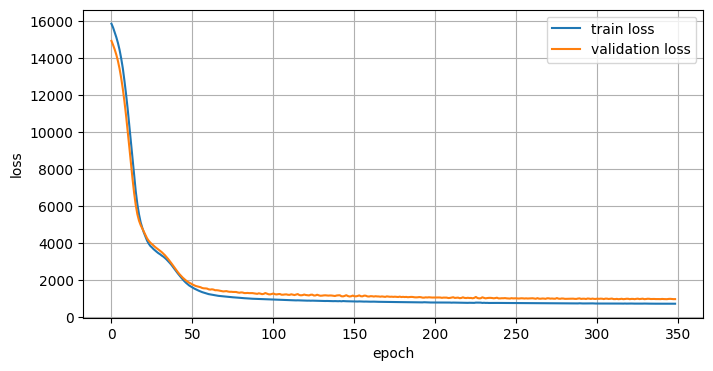

In [ ]:

def section_objective(logits, targets, dimensions):
    valid = targets.ne(-100)
    if not valid.any():
        return logits.sum() * 0.0
    if LOSS_MODE == 'cross_entropy':
        return nn.functional.cross_entropy(logits[valid], targets[valid])
    dim_loss = section_dimension_mse(logits, targets, dimensions)
    if LOSS_MODE == 'dimension_mse':
        return dim_loss
    if LOSS_MODE == 'combined':
        ce_loss = nn.functional.cross_entropy(logits[valid], targets[valid])
        return ce_loss + LAMBDA_DIM * dim_loss
    raise ValueError(f'Unknown LOSS_MODE={LOSS_MODE!r}')
@torch.no_grad()
def evaluate(loader, export_rows=False):
    model.eval()

    total, correct, full_correct, loss_sum = 0, 0, 0, 0.0


    h_total, h_correct = 0, 0
    box_total, box_correct = 0, 0


    floor_stats = {}

    records = []

    for x, y_h, y_box, names in loader:
        x, y_h, y_box = x.to(DEVICE), y_h.to(DEVICE), y_box.to(DEVICE)

        logits_h, logits_box = model(x)

        loss_h = section_objective(logits_h, y_h, H_DIMENSIONS)
        loss_box = section_objective(logits_box, y_box, BOX_DIMENSIONS)

        loss = SECTION_WEIGHT_H * loss_h + SECTION_WEIGHT_BOX * loss_box

        pred_h = torch.argmax(logits_h, dim=-1)
        pred_box = torch.argmax(logits_box, dim=-1)

        # --------------------------------

        # --------------------------------
        all_pred = torch.cat([pred_h, pred_box], dim=1)
        all_true = torch.cat([y_h, y_box], dim=1)

        valid = all_true.ne(-100)
        matches = all_pred.eq(all_true) & valid
        correct += matches.sum().item()
        total += valid.sum().item()


        full_correct += (matches | ~valid).all(1).sum().item()

        # --------------------------------

        # --------------------------------
        h_valid = y_h.ne(-100)
        h_correct += (pred_h.eq(y_h) & h_valid).sum().item()
        h_total += h_valid.sum().item()

        # --------------------------------

        # --------------------------------
        box_valid = y_box.ne(-100)
        box_correct += (pred_box.eq(y_box) & box_valid).sum().item()
        box_total += box_valid.sum().item()

        # --------------------------------

        # --------------------------------
        for slot_idx, (slot, kind) in enumerate(zip(SLOTS, SLOT_TYPES)):


            if ':' in slot:
                floor = slot.split(':')[1]
            else:
                floor = slot

            if floor not in floor_stats:
                floor_stats[floor] = {
                    'correct': 0,
                    'total': 0
                }

            if kind == 'h':
                pred = pred_h[:, sum(
                    1 for s, k in zip(SLOTS[:slot_idx], SLOT_TYPES[:slot_idx])
                    if k == 'h'
                )]

                true = y_h[:, sum(
                    1 for s, k in zip(SLOTS[:slot_idx], SLOT_TYPES[:slot_idx])
                    if k == 'h'
                )]

            else:
                pred = pred_box[:, sum(
                    1 for s, k in zip(SLOTS[:slot_idx], SLOT_TYPES[:slot_idx])
                    if k == 'box'
                )]

                true = y_box[:, sum(
                    1 for s, k in zip(SLOTS[:slot_idx], SLOT_TYPES[:slot_idx])
                    if k == 'box'
                )]

            active = true.ne(-100)
            floor_stats[floor]['correct'] += (pred.eq(true) & active).sum().item()
            floor_stats[floor]['total'] += active.sum().item()

        loss_sum += loss.item() * len(names)

        # --------------------------------

        # --------------------------------
        if export_rows:
            for b, name in enumerate(names):

                hi = bi = 0

                for slot, kind in zip(SLOTS, SLOT_TYPES):

                    if kind == 'h':
                        p = pred_h[b, hi].item()
                        t = y_h[b, hi].item()
                        hi += 1
                        catalog = H_CATALOG

                    else:
                        p = pred_box[b, bi].item()
                        t = y_box[b, bi].item()
                        bi += 1
                        catalog = BOX_CATALOG


                    if t == -100:
                        continue
                    if not (0 <= t < len(catalog)):
                        raise ValueError(
                            f'Invalid target index: file={name}, slot={slot}, '
                            f'target_id={t}, catalog_size={len(catalog)}, type={kind}'
                        )
                    if not (0 <= p < len(catalog)):
                        raise ValueError(
                            f'Invalid prediction index: file={name}, slot={slot}, '
                            f'predicted_id={p}, catalog_size={len(catalog)}, type={kind}'
                        )
                    records.append({
                        'file_name': name,
                        'slot': slot,
                        'section_type': kind,
                        'predicted_catalog': catalog[p]['name'],
                        'true_catalog': catalog[t]['name'],
                        'is_correct': p == t
                    })

    n_files = len(loader.dataset)

    return {
        'loss': loss_sum / n_files,


        'slot_accuracy': correct / max(total, 1),


        'h_accuracy': h_correct / max(h_total, 1),


        'box_accuracy': box_correct / max(box_total, 1),


        'building_exact_match': full_correct / n_files,


        'floor_stats': floor_stats,

        'records': records
    }


CHECKPOINT_SIGNATURE = {
    'feature_normalization': FEATURE_NORMALIZATION, 'slots': SLOTS, 'slot_types': SLOT_TYPES,
    'h_catalog': H_CATALOG, 'box_catalog': BOX_CATALOG, 'max_spans': MAX_SPANS,
    'min_span_mm': MIN_SPAN_MM, 'loss_mode': LOSS_MODE, 'lambda_dim': LAMBDA_DIM,
    'section_weights': (SECTION_WEIGHT_H, SECTION_WEIGHT_BOX),
    'model_config': {'class': 'SimpleDNN', 'n_features': len(FEATURE_NORMALIZATION),
        'n_h_slots': N_H_SLOTS, 'n_box_slots': N_BOX_SLOTS,
        'n_h_catalog': len(H_CATALOG), 'n_box_catalog': len(BOX_CATALOG), 'hidden_layers': (128, 128)},
}
def _dataset_fingerprint():
    digest = hashlib.sha256()
    for split in ('train', 'val'):
        digest.update(split.encode('utf-8'))
        for path in sorted((DATASET_ROOT / split).glob('*.csv')):
            digest.update(path.name.encode('utf-8'))
            with path.open('rb') as f:
                for chunk in iter(lambda: f.read(1024 * 1024), b''): digest.update(chunk)
    return digest.hexdigest()
CHECKPOINT_SIGNATURE['dataset_fingerprint'] = _dataset_fingerprint()
def _try_reuse_checkpoint():
    if not CHECKPOINT_PATH.is_file(): return False, 'チェックポイントがありません'
    try:
        try: saved = torch.load(CHECKPOINT_PATH, map_location='cpu', weights_only=False)
        except TypeError: saved = torch.load(CHECKPOINT_PATH, map_location='cpu')
        if not isinstance(saved, dict): return False, '形式が辞書ではありません'
        if saved.get('checkpoint_signature') != CHECKPOINT_SIGNATURE: return False, '署名が一致しません'
        for key, expected in (('feature_normalization', FEATURE_NORMALIZATION), ('slots', SLOTS),
             ('slot_types', SLOT_TYPES), ('h_catalog', H_CATALOG), ('box_catalog', BOX_CATALOG)):
            if saved.get(key) != expected: return False, f'{key} が一致しません'
        if not np.array_equal(np.asarray(saved.get('feature_min')), feature_min): return False, 'feature_min が一致しません'
        if not np.array_equal(np.asarray(saved.get('feature_max')), feature_max): return False, 'feature_max が一致しません'
        model.load_state_dict(saved['model_state_dict'], strict=True)
        model.to(DEVICE)
        return True, '互換性を確認しました'
    except Exception as exc:

        model.load_state_dict(SimpleDNN(len(FEATURE_NORMALIZATION), N_H_SLOTS, N_BOX_SLOTS, len(H_CATALOG), len(BOX_CATALOG)).state_dict())
        model.to(DEVICE)
        return False, f'読み込み検証に失敗しました: {exc}'
@torch.no_grad()
def constraint_metrics(samples, pairs, batch_size=CONSTRAINT_EVAL_BATCH_SIZE):
    """Evaluate expected-height violations for an oriented set of constraint pairs."""
    if not pairs:
        return {'valid_pairs': 0, 'violated_pairs': 0, 'violation_rate': 0.0, 'max_violation': 0.0, 'mean_violation': 0.0, 'satisfied_rate': 0.0}
    model.eval()
    x_all = torch.stack([normalized_model_input(sample) for sample in samples]).to(DEVICE)
    violations = []
    for start in range(0, len(pairs), batch_size):
        batch = pairs[start:start + batch_size]
        larger = torch.tensor([p[0] for p in batch], device=DEVICE)
        smaller = torch.tensor([p[1] for p in batch], device=DEVICE)
        slots = torch.tensor([p[2] for p in batch], device=DEVICE)
        logits_large, _ = model(x_all[larger])
        logits_small, _ = model(x_all[smaller])
        row = torch.arange(len(batch), device=DEVICE)
        h_large = logits_large[row, slots].softmax(-1) @ H_DIMENSIONS[:, 0]
        h_small = logits_small[row, slots].softmax(-1) @ H_DIMENSIONS[:, 0]
        violations.append((h_small - h_large).cpu())
    values = torch.cat(violations)
    return {'valid_pairs': len(pairs), 'violated_pairs': int((values > 0).sum()),
            'violation_rate': float((values > 0).float().mean()),
            'max_violation': float(values.max()), 'mean_violation': float(values.mean()), 'satisfied_rate': float((values <= 0).float().mean())}

VAL_CONSTRAINT_PAIRS = generate_constraint_pairs(val_samples)
TEST_CONSTRAINT_PAIRS = generate_constraint_pairs(test_samples)

reuse_checkpoint, checkpoint_status = _try_reuse_checkpoint()
print(f'Checkpoint: {CHECKPOINT_PATH} ({checkpoint_status})')
history_path = TRAINING_HISTORY_PATH
history = None
if reuse_checkpoint:
    if history_path.is_file(): history = pd.read_csv(history_path).to_dict(orient='list')
    else: print('学習履歴CSVがないため、学習曲線は省略します。')
else:
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=15)
    constraint_lambdas = torch.zeros(len(TRAIN_CONSTRAINT_PAIRS), dtype=torch.float32, device=DEVICE)
    best_state, best_val, wait = None, float('inf'), 0
    history = {'epoch': [], 'train_loss': [], 'val_loss': [], 'val_slot_accuracy': [], 'val_h_accuracy': [], 'val_box_accuracy': [], 'val_building_exact_match': [], 'learning_rate': [], 'val_constraint_violation_rate': [], 'val_constraint_max_violation': [], 'val_constraint_satisfied_rate': []}
    for epoch in range(1, EPOCHS + 1):
        model.train(); train_loss = 0.0
        for x, y_h, y_box, _ in train_loader:
            x, y_h, y_box = x.to(DEVICE), y_h.to(DEVICE), y_box.to(DEVICE)
            optimizer.zero_grad(set_to_none=True); logits_h, logits_box = model(x)
            data_loss = SECTION_WEIGHT_H * section_objective(logits_h, y_h, H_DIMENSIONS) + SECTION_WEIGHT_BOX * section_objective(logits_box, y_box, BOX_DIMENSIONS)
            loss = data_loss
            sampled_pair_ids = None
            pair_violations = None
            if USE_LAGRANGIAN_CONSTRAINTS and len(TRAIN_CONSTRAINT_PAIRS):
                count = min(CONSTRAINT_BATCH_SIZE, len(TRAIN_CONSTRAINT_PAIRS))
                sampled_pair_ids = np.random.choice(len(TRAIN_CONSTRAINT_PAIRS), size=count, replace=False)
                selected = [TRAIN_CONSTRAINT_PAIRS[int(i)] for i in sampled_pair_ids]
                larger = torch.tensor([p[0] for p in selected], device=DEVICE)
                smaller = torch.tensor([p[1] for p in selected], device=DEVICE)
                slots = torch.tensor([p[2] for p in selected], device=DEVICE)
                ordered_indices = torch.cat((larger, smaller))
                x_constraints = TRAIN_CONSTRAINT_INPUTS[ordered_indices]
                constraint_logits, _ = model(x_constraints)
                row = torch.arange(count, device=DEVICE)
                h_large = constraint_logits[:count][row, slots].softmax(-1) @ H_DIMENSIONS[:, 0]
                h_small = constraint_logits[count:][row, slots].softmax(-1) @ H_DIMENSIONS[:, 0]
                pair_violations = h_small - h_large
                dual = constraint_lambdas[torch.as_tensor(sampled_pair_ids, device=DEVICE)]
                loss = data_loss + (dual * pair_violations).mean()
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); optimizer.step()
            if sampled_pair_ids is not None and pair_violations is not None:
                ids = torch.as_tensor(sampled_pair_ids, device=DEVICE)
                with torch.no_grad():
                    constraint_lambdas[ids] = torch.clamp(constraint_lambdas[ids] + LAGRANGE_LR * pair_violations.detach(), min=0.0)
            train_loss += data_loss.item() * len(x)
        val = evaluate(val_loader); train_loss /= len(train_loader.dataset); scheduler.step(val['loss'])
        val_constraint = constraint_metrics(val_samples, VAL_CONSTRAINT_PAIRS)
        for key, value in [('epoch', epoch), ('train_loss', train_loss), ('val_loss', val['loss']), ('val_slot_accuracy', val['slot_accuracy']), ('val_h_accuracy', val['h_accuracy']), ('val_box_accuracy', val['box_accuracy']), ('val_building_exact_match', val['building_exact_match']), ('learning_rate', optimizer.param_groups[0]['lr']), ('val_constraint_violation_rate', val_constraint['violation_rate']), ('val_constraint_max_violation', val_constraint['max_violation']), ('val_constraint_satisfied_rate', val_constraint['satisfied_rate'])]: history[key].append(value)
        if val['loss'] < best_val:
            best_val, wait = val['loss'], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else: wait += 1
        if epoch == 1 or epoch % 20 == 0: print(f'epoch={epoch:03d} train_loss={train_loss:.4f} val_loss={val["loss"]:.4f} val_acc={val["slot_accuracy"]:.3f}')
        if wait >= PATIENCE: print(f'Early stopping at epoch {epoch}; best val loss={best_val:.4f}'); break
    if best_state is None: raise RuntimeError('有効な最良モデルを取得できませんでした。')
    model.load_state_dict(best_state); model.to(DEVICE)
    pd.DataFrame(history).to_csv(history_path, index=False, encoding='utf-8-sig')
    torch.save({'model_state_dict': model.state_dict(), 'checkpoint_signature': CHECKPOINT_SIGNATURE,
        'feature_min': feature_min, 'feature_max': feature_max, 'feature_normalization': FEATURE_NORMALIZATION,
        'slots': SLOTS, 'slot_types': SLOT_TYPES, 'h_catalog': H_CATALOG, 'box_catalog': BOX_CATALOG}, CHECKPOINT_PATH)
    print(f'学習済みモデルを保存しました: {CHECKPOINT_PATH}')
if history and history.get('train_loss') and history.get('val_loss'):
    plt.figure(figsize=(8, 4)); plt.plot(history['train_loss'], label='train loss'); plt.plot(history['val_loss'], label='validation loss')
    plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.grid(); plt.show()


## Test evaluation and exports

In [ ]:

test_result = evaluate(test_loader, export_rows=True)

print("=" * 50)
print("Test Results")
print("=" * 50)

print(f"Loss                  : {test_result['loss']:.4f}")
print(f"Slot Accuracy         : {test_result['slot_accuracy']:.4f}")
print(f"H (Beam) Accuracy     : {test_result['h_accuracy']:.4f}")
print(f"BOX (Column) Accuracy : {test_result['box_accuracy']:.4f}")
print(f"Building Exact Match  : {test_result['building_exact_match']:.4f}")

print("\n" + "=" * 50)
print("Accuracy by Floor")
print("=" * 50)

for floor, stats in test_result['floor_stats'].items():
    accuracy = stats['correct'] / stats['total']
    print(
        f"{floor:>4s} : "
        f"{accuracy:.4f} "
        f"({stats['correct']}/{stats['total']})"
    )


predictions = pd.DataFrame(test_result['records'])

train_x = np.stack([sample.x for sample in train_samples]); train_lo, train_hi = train_x.min(0), train_x.max(0)
input_x = np.stack([sample.x for sample in test_samples]); outside = ((input_x < train_lo) | (input_x > train_hi)).any(1)
conf_by_file = {}; model.eval()
with torch.inference_mode():
    for x, yh, yb, names in test_loader:
        ph, pb = model(x.to(DEVICE))
        for i, name in enumerate(names):
            probs = []
            if yh.shape[1]: probs.extend(ph[i].softmax(-1).max(-1).values.cpu().tolist())
            if yb.shape[1]: probs.extend(pb[i].softmax(-1).max(-1).values.cpu().tolist())
            conf_by_file[name] = min(probs) if probs else 1.0
anomaly = pd.DataFrame({'file_name': [sample.file_name for sample in test_samples],
    'min_slot_confidence': [conf_by_file[sample.file_name] for sample in test_samples], 'outside_train_feature_range': outside})
anomaly['anomaly_candidate'] = (anomaly.min_slot_confidence < 0.50) | anomaly.outside_train_feature_range
anomaly.to_csv(OUTPUT_DIR / 'anomaly_candidates.csv', index=False, encoding='utf-8-sig')
print('異常候補（要確認）:', int(anomaly.anomaly_candidate.sum()), '/', len(anomaly))

def _catalog_dimensions(name,kind):
    catalog=H_CATALOG if kind=='h' else BOX_CATALOG
    values=next(r['values'] for r in catalog if r['name']==name)
    return {'H':values[0] if kind=='h' else np.nan,'B':values[1] if kind=='h' else np.nan,
            'tw':values[2] if kind=='h' else np.nan,'tf':values[3] if kind=='h' else np.nan,
            'D':values[0] if kind=='box' else np.nan,'t':values[1] if kind=='box' else np.nan}
for prefix,col in [('pred','predicted_catalog'),('true','true_catalog')]:
    dims=pd.DataFrame([_catalog_dimensions(r[col],r['section_type']) for _,r in predictions.iterrows()],index=predictions.index)
    predictions[[f'{prefix}_{c}' for c in dims.columns]]=dims
PREDICTIONS_PATH.parent.mkdir(parents=True, exist_ok=True)
predictions.to_csv(PREDICTIONS_PATH, index=False, encoding='utf-8-sig')



print(f'Saved predictions: {PREDICTIONS_PATH}')
print(predictions.head(20).to_string(index=False))

Test Results
Loss                  : 731.7809
Slot Accuracy         : 0.0337
H (Beam) Accuracy     : 0.0281
BOX (Column) Accuracy : 0.0494
Building Exact Match  : 0.0000

Accuracy by Floor
 2FL : 0.0075 (2/265)
 3FL : 0.0000 (0/154)
 4FL : 0.0000 (0/108)
 5FL : 0.0000 (0/48)
 RFL : 0.0669 (17/254)
 1FL : 0.1333 (12/90)
異常候補（要確認）: 90 / 90
Saved predictions: /content/drive/My Drive/research/DNN6/dnn_result/test_catalog_predictions_lagrangian.csv
                              file_name          slot section_type  predicted_catalog      true_catalog  is_correct  pred_H  pred_B  pred_tw  pred_tf  pred_D  pred_t  true_H  true_B  true_tw  true_tf  true_D  true_t
F1_X1_5000_Y1_4000_H3000_W8p0_model.csv  beam:RFL:GX1            h     H-175x90x5x8x8   H-194x150x6x9x8       False   175.0    90.0      5.0      8.0     NaN     NaN   200.0   150.0      6.0      9.0     NaN     NaN
F1_X1_5000_Y1_4000_H3000_W8p0_model.csv  beam:RFL:GY1            h    H-148x100x6x9x8   H-148x100x6x9x8        True   15

In [ ]:
predictions

,file_name,slot,section_type,predicted_catalog,true_catalog,is_correct,pred_H,pred_B,pred_tw,pred_tf,pred_D,pred_t,true_H,true_B,true_tw,true_tf,true_D,true_t
0,F1_X1_5000_Y1_4000_H3000_W8p0_model.csv,beam:RFL:GX1,h,H-175x90x5x8x8,H-194x150x6x9x8,False,175.0,90.0,5.0,8.0,NaN,NaN,200.0,150.0,6.0,9.0,NaN,NaN
1,F1_X1_5000_Y1_4000_H3000_W8p0_model.csv,beam:RFL:GY1,h,H-148x100x6x9x8,H-148x100x6x9x8,True,150.0,100.0,6.0,9.0,NaN,NaN,150.0,100.0,6.0,9.0,NaN,NaN
2,F1_X1_5000_Y1_4000_H3000_W8p0_model.csv,column:1FL:C1,box,B-150x150x6x15,B-150x150x6x15,True,NaN,NaN,NaN,NaN,150.0,6.0,NaN,NaN,NaN,NaN,150.0,6.0
3,F1_X2_8000_Y1_4000_H3000_W7p0_model.csv,beam:RFL:GX1,h,H-175x90x5x8x8,H-350x175x7x11x13,False,175.0,90.0,5.0,8.0,NaN,NaN,350.0,175.0,7.0,11.0,NaN,NaN
4,F1_X2_8000_Y1_4000_H3000_W7p0_model.csv,beam:RFL:GY1,h,H-148x100x6x9x8,H-350x175x7x11x13,False,150.0,100.0,6.0,9.0,NaN,NaN,350.0,175.0,7.0,11.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,F5_X6_9000_Y1_4000_H3000_W6p5_model.csv,column:1FL:C1,box,B-150x150x6x15,B-350x350x14x35,False,NaN,NaN,NaN,NaN,150.0,6.0,NaN,NaN,NaN,NaN,350.0,14.0
915,F5_X6_9000_Y1_4000_H3000_W6p5_model.csv,column:2FL:C1,box,B-150x150x6x15,B-350x350x12x30,False,NaN,NaN,NaN,NaN,150.0,6.0,NaN,NaN,NaN,NaN,350.0,12.0
916,F5_X6_9000_Y1_4000_H3000_W6p5_model.csv,column:3FL:C1,box,B-175x175x9x22.5,B-350x350x14x35,False,NaN,NaN,NaN,NaN,175.0,9.0,NaN,NaN,NaN,NaN,350.0,14.0
917,F5_X6_9000_Y1_4000_H3000_W6p5_model.csv,column:4FL:C1,box,B-150x150x6x15,B-350x350x12x30,False,NaN,NaN,NaN,NaN,150.0,6.0,NaN,NaN,NaN,NaN,350.0,12.0


In [ ]:

TRAIN_EVAL_PAIRS = generate_constraint_pairs(train_samples)
for split_name, split_samples, split_pairs in (
    ('train', train_samples, TRAIN_EVAL_PAIRS),
    ('validation', val_samples, VAL_CONSTRAINT_PAIRS),
    ('test', test_samples, TEST_CONSTRAINT_PAIRS),
):
    print(split_name, constraint_metrics(split_samples, split_pairs))


train {'valid_pairs': 47850, 'violated_pairs': 0, 'violation_rate': 0.0, 'max_violation': -0.8421630859375, 'mean_violation': -37.05220413208008, 'satisfied_rate': 1.0}
validation {'valid_pairs': 753, 'violated_pairs': 0, 'violation_rate': 0.0, 'max_violation': -1.531768798828125, 'mean_violation': -32.208526611328125, 'satisfied_rate': 1.0}
test {'valid_pairs': 604, 'violated_pairs': 0, 'violation_rate': 0.0, 'max_violation': -1.75726318359375, 'mean_violation': -33.67647933959961, 'satisfied_rate': 1.0}


## Supplementary visualization

In [ ]:
from IPython.display import display


def _catalog_dimensions(name,kind):
    catalog=H_CATALOG if kind=='h' else BOX_CATALOG
    values=next(r['values'] for r in catalog if r['name']==name)
    return {'H':values[0] if kind=='h' else np.nan,'B':values[1] if kind=='h' else np.nan,
            'tw':values[2] if kind=='h' else np.nan,'tf':values[3] if kind=='h' else np.nan,
            'D':values[0] if kind=='box' else np.nan,'t':values[1] if kind=='box' else np.nan}
for prefix,col in [('pred','predicted_catalog'),('true','true_catalog')]:
    dims=pd.DataFrame([_catalog_dimensions(r[col],r['section_type']) for _,r in predictions.iterrows()],index=predictions.index)
    predictions[[f'{prefix}_{c}' for c in dims.columns]]=dims


TEST_META = {sm.file_name: sm.meta for sm in test_samples}
def _file_conditions(name):
    m=TEST_META[name]; header,rows=table_after_marker(read_text(DATASET_ROOT/'test'/name),'name=スパン割')
    cols=[i for i,col in enumerate(header) if col.startswith('スパン')]
    sp={r[0].strip():[float(r[i]) for i in cols if i<len(r) and r[i].strip()] for r in rows}
    return {'階数':m['floors'],'xスパン数':m['nx'],'yスパン数':m['ny'],'荷重':m['load'],'Xスパン平均':float(np.mean(sp['X'])),'Yスパン平均':float(np.mean(sp['Y']))}
plot_df=pd.concat([predictions.copy(),pd.DataFrame([_file_conditions(n) for n in predictions.file_name],index=predictions.index)],axis=1)
def plot_matched_section(section='h',slot='beam:3FL:GX1',x_axis='xスパン数',dimension='H'):
    d=plot_df[(plot_df.section_type==section)&(plot_df.slot==slot)].copy()
    if d.empty: print('該当slotがありません:',slot); return
    controls=[c for c in ['階数','xスパン数','yスパン数','荷重','Xスパン平均','Yスパン平均'] if c!=x_axis]
    scale=d[controls].std().replace(0,1).fillna(1); rows=[]
    for xv,g in d.groupby(x_axis):
        ref=d[d[x_axis]!=xv]
        if ref.empty: rows.extend(g.to_dict('records')); continue
        anchor=g.iloc[0][controls].astype(float); dist=((ref[controls].astype(float)-anchor)/scale).pow(2).sum(1)
        rows.extend(g.head(3).to_dict('records')); rows.extend(ref.loc[dist.nsmallest(min(3,len(dist))).index].to_dict('records'))
    q=pd.DataFrame(rows).drop_duplicates('file_name').sort_values(x_axis)
    q.plot(x=x_axis,y=['pred_'+dimension,'true_'+dimension],marker='o',figsize=(9,5),title=f'{slot}: {dimension} vs {x_axis} (近い条件で比較)')
    plt.ylabel(f'{dimension} 呼び寸(mm)'); plt.grid(True); plt.tight_layout(); plt.show()
    print('比較対象:',len(q),'件')



print('異常候補CSV:',OUTPUT_DIR/'anomaly_candidates.csv')

異常候補CSV: /content/drive/My Drive/research/DNN6/dnn_result/anomaly_candidates.csv


## Supplementary plots

In [8]:
#assign again
from pathlib import Path
PROJECT_ROOT = Path.cwd()

DATASET_ROOT = Path(r'/content/drive/MyDrive/research/dataset-dnn6') if Path(r'/content/drive/MyDrive/research/dataset-dnn6').exists() else Path('/content/drive/MyDrive/research/dataset-dnn6')
CATALOG_ROOT = DATASET_ROOT / 'dnn-catalog-1107'
H_CATALOG_FILE = 'JIS_SN_medium_narrow_H_list_DNN.csv'
BOX_CATALOG_FILE = 'BCR_square_tube_list_DNN.csv'
OUTPUT_DIR = PROJECT_ROOT / 'dnn_result'
print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATASET_ROOT:', DATASET_ROOT)
print('CATALOG_ROOT:', CATALOG_ROOT)
print('H catalog file:', H_CATALOG_FILE, '/ box catalog file:', BOX_CATALOG_FILE)
print('OUTPUT_DIR:', OUTPUT_DIR)

PROJECT_ROOT: /content
DATASET_ROOT: /content/drive/MyDrive/research/dataset-dnn6
CATALOG_ROOT: /content/drive/MyDrive/research/dataset-dnn6/dnn-catalog-1107
H catalog file: JIS_SN_medium_narrow_H_list_DNN.csv / box catalog file: BCR_square_tube_list_DNN.csv
OUTPUT_DIR: /content/dnn_result


In [9]:
# !pip install japanize-matplotlib

In [10]:
import re
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import os
from google.colab import files
#コード中で、
# import japanize_matplotlib

#上書きされたあとで、
# japanize_matplotlib.japanize()

In [11]:
from google.colab import drive
import pandas as pd

# 1. Mount Google Drive (it will ask you to authorize access via a pop-up window)
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
# 2. Load the CSV file using its path in your Drive
# (Adjust the path below to match where your file is located)
file_path = '/content/drive/My Drive/research/DNN6/dnn_result/test_catalog_predictions_lagrangian.csv'
df = pd.read_csv(file_path)

# Display the first few rows
df.head()

,file_name,slot,section_type,predicted_catalog,true_catalog,is_correct,pred_H,pred_B,pred_tw,pred_tf,pred_D,pred_t,true_H,true_B,true_tw,true_tf,true_D,true_t
0,F1_X1_5000_Y1_4000_H3000_W8p0_model.csv,beam:RFL:GX1,h,H-175x90x5x8x8,H-194x150x6x9x8,False,175.0,90.0,5.0,8.0,NaN,NaN,200.0,150.0,6.0,9.0,NaN,NaN
1,F1_X1_5000_Y1_4000_H3000_W8p0_model.csv,beam:RFL:GY1,h,H-148x100x6x9x8,H-148x100x6x9x8,True,150.0,100.0,6.0,9.0,NaN,NaN,150.0,100.0,6.0,9.0,NaN,NaN
2,F1_X1_5000_Y1_4000_H3000_W8p0_model.csv,column:1FL:C1,box,B-150x150x6x15,B-150x150x6x15,True,NaN,NaN,NaN,NaN,150.0,6.0,NaN,NaN,NaN,NaN,150.0,6.0
3,F1_X2_8000_Y1_4000_H3000_W7p0_model.csv,beam:RFL:GX1,h,H-175x90x5x8x8,H-350x175x7x11x13,False,175.0,90.0,5.0,8.0,NaN,NaN,350.0,175.0,7.0,11.0,NaN,NaN
4,F1_X2_8000_Y1_4000_H3000_W7p0_model.csv,beam:RFL:GY1,h,H-148x100x6x9x8,H-350x175x7x11x13,False,150.0,100.0,6.0,9.0,NaN,NaN,350.0,175.0,7.0,11.0,NaN,NaN


In [19]:
print(df.head)

<bound method NDFrame.head of                                    file_name           slot section_type  \
0    F1_X1_5000_Y1_4000_H3000_W8p0_model.csv   beam:RFL:GX1            h   
1    F1_X1_5000_Y1_4000_H3000_W8p0_model.csv   beam:RFL:GY1            h   
2    F1_X1_5000_Y1_4000_H3000_W8p0_model.csv  column:1FL:C1          box   
3    F1_X2_8000_Y1_4000_H3000_W7p0_model.csv   beam:RFL:GX1            h   
4    F1_X2_8000_Y1_4000_H3000_W7p0_model.csv   beam:RFL:GY1            h   
..                                       ...            ...          ...   
914  F5_X6_9000_Y1_4000_H3000_W6p5_model.csv  column:1FL:C1          box   
915  F5_X6_9000_Y1_4000_H3000_W6p5_model.csv  column:2FL:C1          box   
916  F5_X6_9000_Y1_4000_H3000_W6p5_model.csv  column:3FL:C1          box   
917  F5_X6_9000_Y1_4000_H3000_W6p5_model.csv  column:4FL:C1          box   
918  F5_X6_9000_Y1_4000_H3000_W6p5_model.csv  column:5FL:C1          box   

    predicted_catalog       true_catalog  is_correct  pre

In [13]:
df

,file_name,slot,section_type,predicted_catalog,true_catalog,is_correct,pred_H,pred_B,pred_tw,pred_tf,pred_D,pred_t,true_H,true_B,true_tw,true_tf,true_D,true_t
0,F1_X1_5000_Y1_4000_H3000_W8p0_model.csv,beam:RFL:GX1,h,H-175x90x5x8x8,H-194x150x6x9x8,False,175.0,90.0,5.0,8.0,NaN,NaN,200.0,150.0,6.0,9.0,NaN,NaN
1,F1_X1_5000_Y1_4000_H3000_W8p0_model.csv,beam:RFL:GY1,h,H-148x100x6x9x8,H-148x100x6x9x8,True,150.0,100.0,6.0,9.0,NaN,NaN,150.0,100.0,6.0,9.0,NaN,NaN
2,F1_X1_5000_Y1_4000_H3000_W8p0_model.csv,column:1FL:C1,box,B-150x150x6x15,B-150x150x6x15,True,NaN,NaN,NaN,NaN,150.0,6.0,NaN,NaN,NaN,NaN,150.0,6.0
3,F1_X2_8000_Y1_4000_H3000_W7p0_model.csv,beam:RFL:GX1,h,H-175x90x5x8x8,H-350x175x7x11x13,False,175.0,90.0,5.0,8.0,NaN,NaN,350.0,175.0,7.0,11.0,NaN,NaN
4,F1_X2_8000_Y1_4000_H3000_W7p0_model.csv,beam:RFL:GY1,h,H-148x100x6x9x8,H-350x175x7x11x13,False,150.0,100.0,6.0,9.0,NaN,NaN,350.0,175.0,7.0,11.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
914,F5_X6_9000_Y1_4000_H3000_W6p5_model.csv,column:1FL:C1,box,B-150x150x6x15,B-350x350x14x35,False,NaN,NaN,NaN,NaN,150.0,6.0,NaN,NaN,NaN,NaN,350.0,14.0
915,F5_X6_9000_Y1_4000_H3000_W6p5_model.csv,column:2FL:C1,box,B-150x150x6x15,B-350x350x12x30,False,NaN,NaN,NaN,NaN,150.0,6.0,NaN,NaN,NaN,NaN,350.0,12.0
916,F5_X6_9000_Y1_4000_H3000_W6p5_model.csv,column:3FL:C1,box,B-175x175x9x22.5,B-350x350x14x35,False,NaN,NaN,NaN,NaN,175.0,9.0,NaN,NaN,NaN,NaN,350.0,14.0
917,F5_X6_9000_Y1_4000_H3000_W6p5_model.csv,column:4FL:C1,box,B-150x150x6x15,B-350x350x12x30,False,NaN,NaN,NaN,NaN,150.0,6.0,NaN,NaN,NaN,NaN,350.0,12.0


### Member H-Length vs. X-Span Length

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved graph to: /content/dnn_result/Member_H_Length_vs_X_Span_Length.png

Components plotted:
[1] X-Span Length: 4000 mm
    Component: F1_X3_4000_Y1_4000_H3000_W7p0_model.csv | beam:RFL:GX1
    Predicted H:    175.0 mm
    Ground Truth H: 150.0 mm
------------------------------------------------------------------------------------------------------------------------
[2] X-Span Length: 5000 mm
    Component: F1_X1_5000_Y1_4000_H3000_W8p0_model.csv | beam:RFL:GX1
    Predicted H:    175.0 mm
    Ground Truth H: 200.0 mm
------------------------------------------------------------------------------------------------------------------------
[3] X-Span Length: 6000 mm
    Component: F1_X4_6000_Y1_4000_H3000_W6p0_model.csv | beam:RFL:GX1
    Predicted H:    175.0 mm
    Ground Truth H: 200.0 mm
------------------------------------------------------------------------------------------------------------------------
[4] X-Span Length: 7000 mm
    Component: F1_X6_7000_Y1_4000_H3000_W6p5_model.

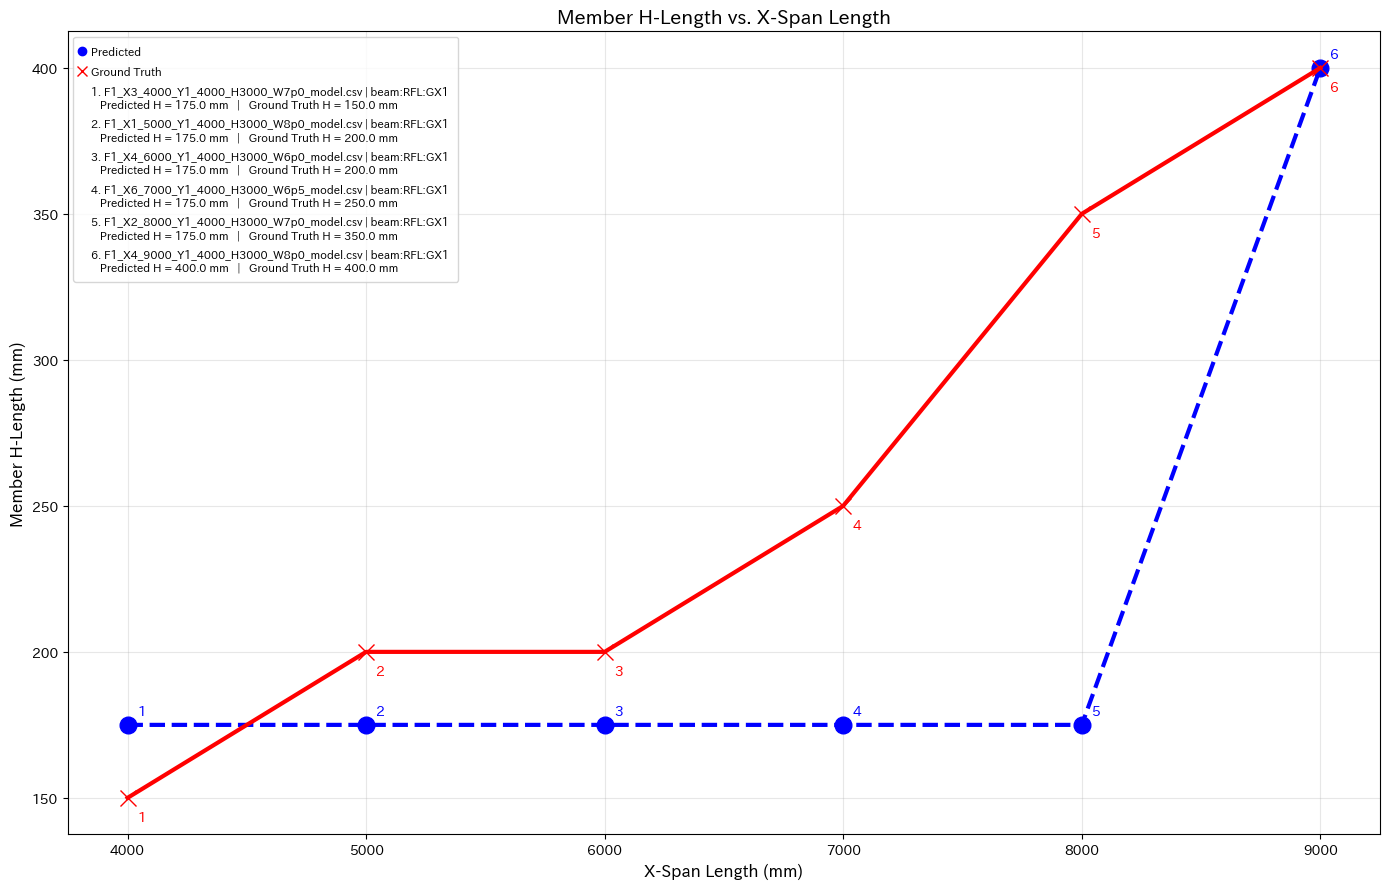

In [16]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# 1. Load CSV
# ============================================================

# Adjust the path below to match where your file is located.
# file_path = '/content/drive/My Drive/research/DNN6/dnn_result/test_catalog_predictions_lagrangian.csv'
# df = pd.read_csv(file_path)


# ============================================================
# 2. Extract X-span length from file_name
# ============================================================

def extract_x_span_length(file_name):
    """
    Extract the X-span length from the file name.

    Example:
        F1_X1_5000_Y1_4000_H3000_W8p0_model.csv

    X1_5000 means:
        X-span count   = 1
        X-span length  = 5000 mm
    """

    match = re.search(
        r'_X\d+_(\d+)_',
        file_name
    )

    if match is None:
        return pd.NA

    return int(match.group(1))


df['x_span_length'] = df['file_name'].apply(
    extract_x_span_length
)


# ============================================================
# 3. Select H-section beams
# ============================================================

df_h = df[
    (df['section_type'] == 'h') &
    (df['slot'].str.startswith('beam:', na=False))
].copy()


# Remove rows for which the required values are unavailable
df_h = df_h.dropna(
    subset=[
        'x_span_length',
        'pred_H',
        'true_H',
        'file_name',
        'slot'
    ]
)


# ============================================================
# 4. Select ONE data point for each X-span length
# ============================================================

# Sort by X-span length, file name, and slot
# so that the selection is deterministic.
df_h = df_h.sort_values(
    ['x_span_length', 'file_name', 'slot']
)


# Keep only the first row for each X-span length
summary = (
    df_h
    .drop_duplicates(
        subset='x_span_length',
        keep='first'
    )
    .sort_values('x_span_length')
    .reset_index(drop=True)
)


# ============================================================
# 5. Check that data exist
# ============================================================

if summary.empty:
    raise ValueError(
        'No valid H-section beam data were found in the CSV file.'
    )


# ============================================================
# 6. Generate graph
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 9)
)


# ============================================================
# 7. Plot predicted values
# ============================================================

ax.plot(
    summary['x_span_length'],
    summary['pred_H'],
    marker='o',
    linestyle='--',
    color='blue',
    linewidth=2,
    markersize=10,
    label='Predicted'
)


# ============================================================
# 8. Plot ground-truth values
# ============================================================

ax.plot(
    summary['x_span_length'],
    summary['true_H'],
    marker='x',
    linestyle='-',
    color='red',
    linewidth=2,
    markersize=10,
    label='Ground Truth'
)


# ============================================================
# 9. Add numbers to the plotted points
# ============================================================

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    # Number next to predicted point
    ax.annotate(
        str(i),
        xy=(
            row['x_span_length'],
            row['pred_H']
        ),
        xytext=(7, 7),
        textcoords='offset points',
        color='blue',
        fontsize=10,
        fontweight='bold'
    )

    # Number next to ground-truth point
    ax.annotate(
        str(i),
        xy=(
            row['x_span_length'],
            row['true_H']
        ),
        xytext=(7, -17),
        textcoords='offset points',
        color='red',
        fontsize=10,
        fontweight='bold'
    )


# ============================================================
# 10. Create a CUSTOM legend
# ============================================================

# ------------------------------------------------------------
# First: legend entries explaining the two line types
# ------------------------------------------------------------

legend_handles = [
    Line2D(
        [0],
        [0],
        color='blue',
        linestyle='--',
        marker='o',
        linewidth=1.5,
        markersize=6,
        label='Predicted'
    ),

    Line2D(
        [0],
        [0],
        color='red',
        linestyle='-',
        marker='x',
        linewidth=1.5,
        markersize=7,
        label='Ground Truth'
    )
]


# ------------------------------------------------------------
# Second: one legend entry for each numbered component
# ------------------------------------------------------------

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    legend_text = (
        f'{i}. {component_name}\n'
        f'   Predicted H = {row["pred_H"]} mm'
        f'   |   Ground Truth H = {row["true_H"]} mm'
    )

    # No numbered marker is used here.
    # The legend text itself contains the component number.
    legend_handles.append(
        Line2D(
            [0],
            [0],
            color='none',
            linestyle='None',
            marker=None,
            label=legend_text
        )
    )


# ------------------------------------------------------------
# Display the custom legend
# ------------------------------------------------------------

ax.legend(
    handles=legend_handles,
    loc='best',
    fontsize=8,
    frameon=True,
    handlelength=0,
    borderpad=0.8,
    labelspacing=0.8
)

# ============================================================
# 11. Axis labels
# ============================================================

ax.set_xlabel(
    'X-Span Length (mm)',
    fontsize=12
)

ax.set_ylabel(
    'Member H-Length (mm)',
    fontsize=12
)


# ============================================================
# 12. Title
# ============================================================

ax.set_title(
    'Member H-Length vs. X-Span Length',
    fontsize=14
)


# ============================================================
# 13. Grid
# ============================================================

ax.grid(
    True,
    alpha=0.3
)


# ============================================================
# 14. Adjust layout
# ============================================================

plt.tight_layout()


# ============================================================
# 15. Save graph
# ============================================================

save_dir = OUTPUT_DIR

os.makedirs(
    save_dir,
    exist_ok=True
)

output_path = os.path.join(
    save_dir,
    'Member_H_Length_vs_X_Span_Length.png'
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight'
)

files.download(output_path)


# ============================================================
# 16. Output selected components to terminal
# ============================================================

print(
    f'Saved graph to: {output_path}'
)

print('\nComponents plotted:')
print('=' * 120)

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    print(
        f'[{i}] X-Span Length: '
        f'{row["x_span_length"]} mm'
    )

    print(
        f'    Component: {component_name}'
    )

    print(
        f'    Predicted H:    {row["pred_H"]} mm'
    )

    print(
        f'    Ground Truth H: {row["true_H"]} mm'
    )

    print('-' * 120)


print(
    f'Total number of unique X-span lengths plotted: '
    f'{summary["x_span_length"].nunique()}'
)


# ============================================================
# 17. Display graph
# ============================================================

plt.show()

### Member_H_Length_vs_Building_Load

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved graph to: /content/dnn_result/Member_H_Length_vs_Building_Load.png

Components plotted:
[1] Load: 6
    Component: F1_X4_4000_Y1_4000_H3000_W6p0_model.csv | beam:RFL:GX1
    Predicted H:    175.0 mm
    Ground Truth H: 150.0 mm
------------------------------------------------------------------------------------------------------------------------
[2] Load: 6.5
    Component: F1_X4_4000_Y1_4000_H3000_W6p5_model.csv | beam:RFL:GX1
    Predicted H:    175.0 mm
    Ground Truth H: 150.0 mm
------------------------------------------------------------------------------------------------------------------------
[3] Load: 7
    Component: F1_X2_8000_Y1_4000_H3000_W7p0_model.csv | beam:RFL:GX1
    Predicted H:    175.0 mm
    Ground Truth H: 350.0 mm
------------------------------------------------------------------------------------------------------------------------
[4] Load: 7.5
    Component: F1_X3_4000_Y1_4000_H3000_W7p5_model.csv | beam:RFL:GX1
    Predicted H:    175.0 mm
    Grou

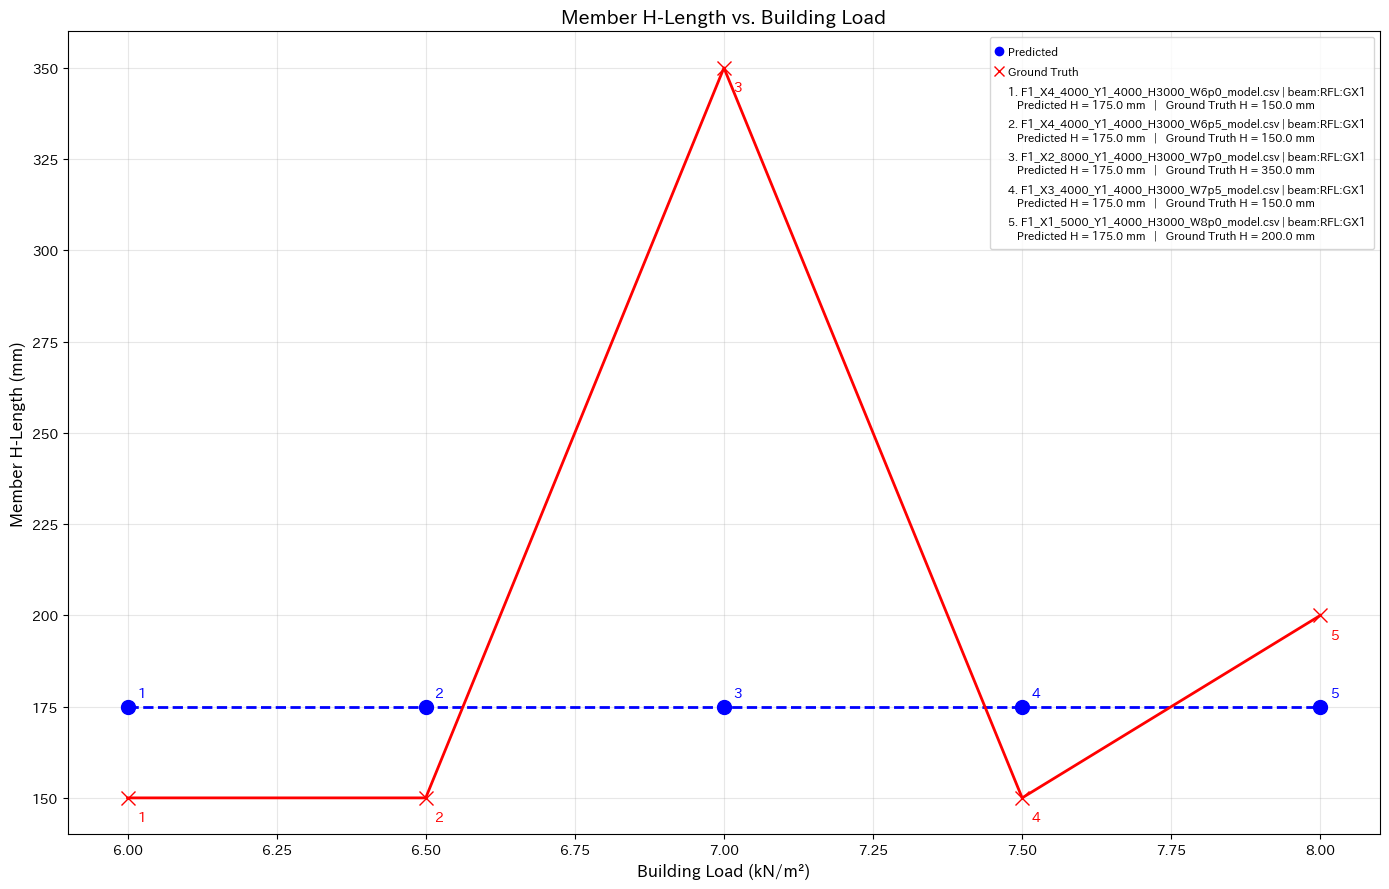

In [21]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# 1. Load CSV
# ============================================================

# Adjust the path below to match where your file is located.
# file_path = '/content/drive/My Drive/research/DNN6/dnn_result/test_catalog_predictions_lagrangian.csv'
# df = pd.read_csv(file_path)


# ============================================================
# 2. Extract building load from file_name
# ============================================================

def extract_load(file_name):
    """
    Extract the building load from the file name.

    Example:
        F1_X1_5000_Y1_4000_H3000_W8p0_model.csv

    W8p0 -> load = 8.0
    """

    match = re.search(
        r'_W([\d.]+p?[\d]*)_',
        file_name
    )

    if match is None:
        return pd.NA

    load_str = match.group(1).replace('p', '.')

    return float(load_str)


df['load'] = df['file_name'].apply(
    extract_load
)


# ============================================================
# 3. Select H-section structural members
# ============================================================

df_h = df[
    (df['section_type'] == 'h') &
    (df['slot'].str.startswith('beam:', na=False))
].copy()


# Remove rows with missing required values
df_h = df_h.dropna(
    subset=[
        'load',
        'pred_H',
        'true_H',
        'file_name',
        'slot'
    ]
)


# ============================================================
# 4. Select ONE specific component for each load value
# ============================================================

# Sort first to make the selection deterministic.
df_h = df_h.sort_values(
    ['load', 'file_name', 'slot']
)


# Keep exactly one component for each load value.
summary = (
    df_h
    .drop_duplicates(
        subset='load',
        keep='first'
    )
    .sort_values('load')
    .reset_index(drop=True)
)


# ============================================================
# 5. Check that data exist
# ============================================================

if summary.empty:
    raise ValueError(
        'No valid H-section beam data were found in the CSV file.'
    )


# ============================================================
# 6. Generate graph
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 9)
)


# ============================================================
# 7. Plot predicted values
# ============================================================

ax.plot(
    summary['load'],
    summary['pred_H'],
    marker='o',
    linestyle='--',
    color='blue',
    linewidth=2,
    markersize=10,
    label='Predicted'
)


# ============================================================
# 8. Plot ground-truth values
# ============================================================

ax.plot(
    summary['load'],
    summary['true_H'],
    marker='x',
    linestyle='-',
    color='red',
    linewidth=2,
    markersize=10,
    label='Ground Truth'
)


# ============================================================
# 9. Add numbers to the plotted points
# ============================================================

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    # Number next to predicted point
    ax.annotate(
        str(i),
        xy=(
            row['load'],
            row['pred_H']
        ),
        xytext=(7, 7),
        textcoords='offset points',
        color='blue',
        fontsize=10,
        fontweight='bold'
    )

    # Number next to ground-truth point
    ax.annotate(
        str(i),
        xy=(
            row['load'],
            row['true_H']
        ),
        xytext=(7, -17),
        textcoords='offset points',
        color='red',
        fontsize=10,
        fontweight='bold'
    )


# ============================================================
# 10. Create a CUSTOM legend
# ============================================================

# ------------------------------------------------------------
# First: legend entries explaining the two line types
# ------------------------------------------------------------

legend_handles = [
    Line2D(
        [0],
        [0],
        color='blue',
        linestyle='--',
        marker='o',
        linewidth=1.5,
        markersize=6,
        label='Predicted'
    ),

    Line2D(
        [0],
        [0],
        color='red',
        linestyle='-',
        marker='x',
        linewidth=1.5,
        markersize=7,
        label='Ground Truth'
    )
]


# ------------------------------------------------------------
# Second: one legend entry for each numbered component
# ------------------------------------------------------------

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    legend_text = (
        f'{i}. {component_name}\n'
        f'   Predicted H = {row["pred_H"]} mm'
        f'   |   Ground Truth H = {row["true_H"]} mm'
    )

    # Invisible legend handle.
    #
    # The component number is included directly in
    # legend_text, so no ① / ② / ③ marker is added.
    legend_handles.append(
        Line2D(
            [0],
            [0],
            color='none',
            linestyle='None',
            marker=None,
            label=legend_text
        )
    )


# ------------------------------------------------------------
# Display the custom legend
# ------------------------------------------------------------

ax.legend(
    handles=legend_handles,
    loc='best',
    fontsize=8,
    frameon=True,
    handlelength=0,
    borderpad=0.8,
    labelspacing=0.8
)


# ============================================================
# 11. Axis labels
# ============================================================

ax.set_xlabel(
    'Building Load (kN/m²)',
    fontsize=12
)

ax.set_ylabel(
    'Member H-Length (mm)',
    fontsize=12
)


# ============================================================
# 12. Title
# ============================================================

ax.set_title(
    'Member H-Length vs. Building Load',
    fontsize=14
)


# ============================================================
# 13. Grid
# ============================================================

ax.grid(
    True,
    alpha=0.3
)


# ============================================================
# 14. Adjust layout
# ============================================================

plt.tight_layout()


# ============================================================
# 15. Save graph
# ============================================================

save_dir = OUTPUT_DIR

os.makedirs(
    save_dir,
    exist_ok=True
)

output_path = os.path.join(
    save_dir,
    'Member_H_Length_vs_Building_Load.png'
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight'
)

files.download(output_path)


# ============================================================
# 16. Output plotted components to terminal
# ============================================================

print(
    f'Saved graph to: {output_path}'
)

print('\nComponents plotted:')
print('=' * 120)

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    print(
        f'[{i}] Load: {row["load"]:g}'
    )

    print(
        f'    Component: {component_name}'
    )

    print(
        f'    Predicted H:    {row["pred_H"]} mm'
    )

    print(
        f'    Ground Truth H: {row["true_H"]} mm'
    )

    print('-' * 120)


print(
    f'Total number of unique load values plotted: '
    f'{summary["load"].nunique()}'
)


# ============================================================
# 17. Display graph
# ============================================================

plt.show()

### Square Steel Section D-Dimension vs. Building Load

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved graph to: /content/dnn_result/Square_Steel_D_Dimension_vs_Building_Load.png

Square steel components plotted:
[1] Load: 6 kN/m²
    Component: F1_X4_4000_Y1_4000_H3000_W6p0_model.csv | column:1FL:C1
    Predicted D:    150.0 mm
    Ground Truth D: 150.0 mm
------------------------------------------------------------------------------------------------------------------------
[2] Load: 6.5 kN/m²
    Component: F1_X4_4000_Y1_4000_H3000_W6p5_model.csv | column:1FL:C1
    Predicted D:    150.0 mm
    Ground Truth D: 150.0 mm
------------------------------------------------------------------------------------------------------------------------
[3] Load: 7 kN/m²
    Component: F1_X2_8000_Y1_4000_H3000_W7p0_model.csv | column:1FL:C1
    Predicted D:    150.0 mm
    Ground Truth D: 150.0 mm
------------------------------------------------------------------------------------------------------------------------
[4] Load: 7.5 kN/m²
    Component: F1_X3_4000_Y1_4000_H3000_W7p5_model.csv | c

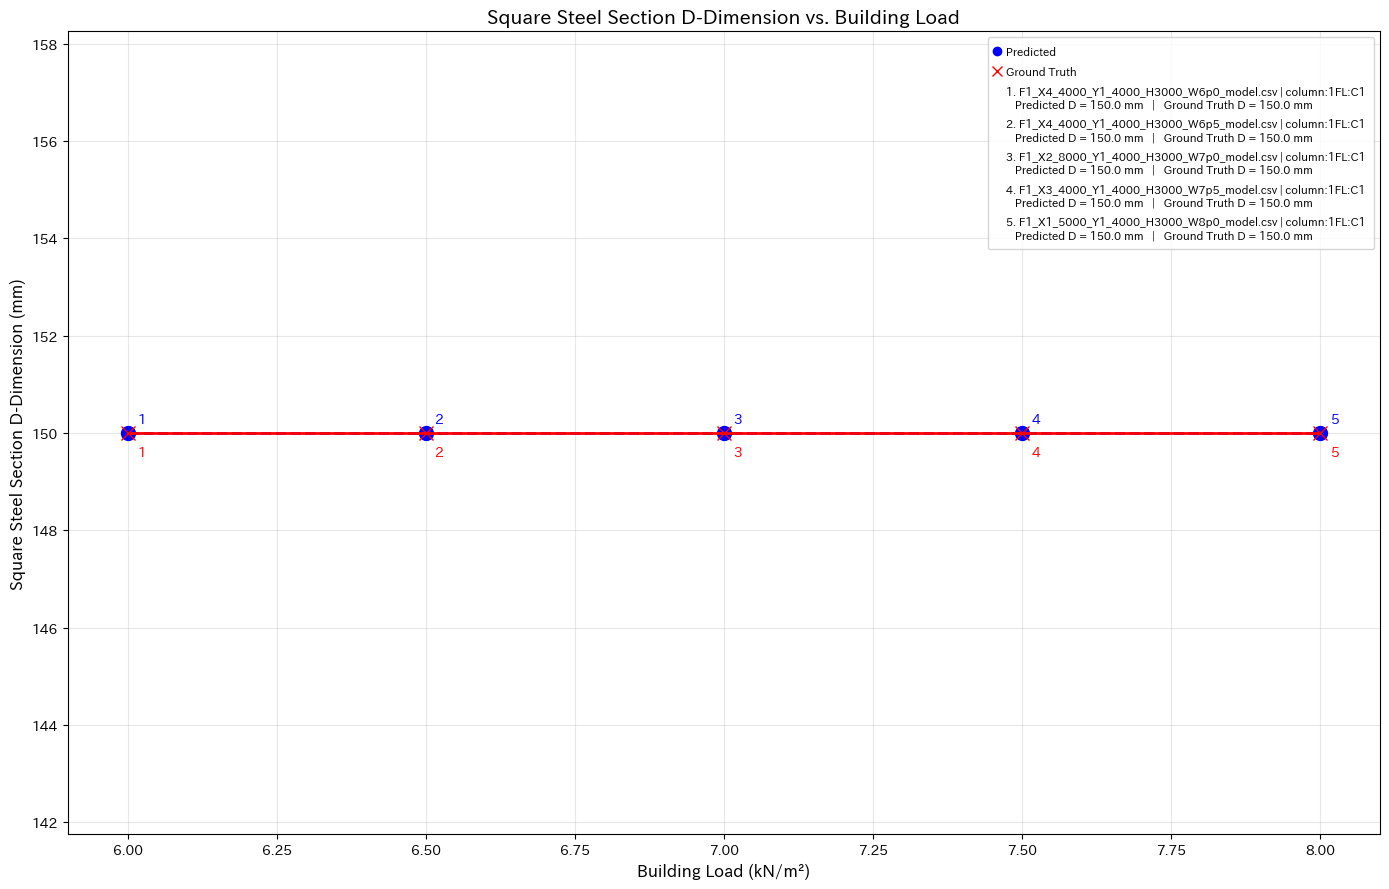

In [20]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# 1. Load CSV
# ============================================================

# Adjust the path below to match where your file is located.
# file_path = '/content/drive/My Drive/research/DNN6/dnn_result/test_catalog_predictions_lagrangian.csv'
# df = pd.read_csv(file_path)


# ============================================================
# 2. Extract building load from file_name
# ============================================================

def extract_load(file_name):
    """
    Extract the building load from the file name.

    Example:
        F1_X1_5000_Y1_4000_H3000_W8p0_model.csv

    W8p0 -> load = 8.0 kN/m²
    """

    match = re.search(
        r'_W([\d.]+p?[\d]*)_',
        file_name
    )

    if match is None:
        return pd.NA

    load_str = match.group(1).replace('p', '.')

    return float(load_str)


# Create/update the load column
df['load'] = df['file_name'].apply(
    extract_load
)


# ============================================================
# 3. Select square steel sections
# ============================================================

# In the provided df:
#
# section_type == 'box'
#
# corresponds to the square steel sections.
#
# We also restrict the selection to column members.

df_box = df[
    (df['section_type'] == 'box') &
    (df['slot'].str.startswith('column:', na=False))
].copy()


# ============================================================
# 4. Remove rows with missing required values
# ============================================================

df_box = df_box.dropna(
    subset=[
        'load',
        'pred_D',
        'true_D',
        'file_name',
        'slot'
    ]
)


# ============================================================
# 5. Select ONE component for each load value
# ============================================================

# Sort first to make the selection deterministic.

df_box = df_box.sort_values(
    ['load', 'file_name', 'slot']
)


# Keep exactly one square-section component
# for each load value.

summary = (
    df_box
    .drop_duplicates(
        subset='load',
        keep='first'
    )
    .sort_values('load')
    .reset_index(drop=True)
)


# ============================================================
# 6. Check that data exist
# ============================================================

if summary.empty:
    raise ValueError(
        'No valid square steel column data were found in the CSV file.'
    )


# ============================================================
# 7. Generate graph
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 9)
)


# ============================================================
# 8. Plot predicted D-dimension
# ============================================================

ax.plot(
    summary['load'],
    summary['pred_D'],
    marker='o',
    linestyle='--',
    color='blue',
    linewidth=2,
    markersize=10,
    label='Predicted'
)


# ============================================================
# 9. Plot ground-truth D-dimension
# ============================================================

ax.plot(
    summary['load'],
    summary['true_D'],
    marker='x',
    linestyle='-',
    color='red',
    linewidth=2,
    markersize=10,
    label='Ground Truth'
)


# ============================================================
# 10. Add numbers to the plotted points
# ============================================================

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    # --------------------------------------------------------
    # Number next to predicted point
    # --------------------------------------------------------

    ax.annotate(
        str(i),
        xy=(
            row['load'],
            row['pred_D']
        ),
        xytext=(7, 7),
        textcoords='offset points',
        color='blue',
        fontsize=10,
        fontweight='bold'
    )

    # --------------------------------------------------------
    # Number next to ground-truth point
    # --------------------------------------------------------

    ax.annotate(
        str(i),
        xy=(
            row['load'],
            row['true_D']
        ),
        xytext=(7, -17),
        textcoords='offset points',
        color='red',
        fontsize=10,
        fontweight='bold'
    )


# ============================================================
# 11. Create custom legend
# ============================================================

# ------------------------------------------------------------
# First: explain the two plotted lines
# ------------------------------------------------------------

legend_handles = [
    Line2D(
        [0],
        [0],
        color='blue',
        linestyle='--',
        marker='o',
        linewidth=1.5,
        markersize=6,
        label='Predicted'
    ),

    Line2D(
        [0],
        [0],
        color='red',
        linestyle='-',
        marker='x',
        linewidth=1.5,
        markersize=7,
        label='Ground Truth'
    )
]


# ------------------------------------------------------------
# Second: add one legend entry for each component
# ------------------------------------------------------------

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    legend_text = (
        f'{i}. {component_name}\n'
        f'   Predicted D = {row["pred_D"]} mm'
        f'   |   Ground Truth D = {row["true_D"]} mm'
    )

    # Invisible handle.
    #
    # The number is contained directly in the legend text.
    legend_handles.append(
        Line2D(
            [0],
            [0],
            color='none',
            linestyle='None',
            marker=None,
            label=legend_text
        )
    )


# ------------------------------------------------------------
# Display the custom legend
# ------------------------------------------------------------

ax.legend(
    handles=legend_handles,
    loc='best',
    fontsize=8,
    frameon=True,
    handlelength=0,
    borderpad=0.8,
    labelspacing=0.8
)


# ============================================================
# 12. Axis labels
# ============================================================

ax.set_xlabel(
    'Building Load (kN/m²)',
    fontsize=12
)

ax.set_ylabel(
    'Square Steel Section D-Dimension (mm)',
    fontsize=12
)


# ============================================================
# 13. Title
# ============================================================

ax.set_title(
    'Square Steel Section D-Dimension vs. Building Load',
    fontsize=14
)


# ============================================================
# 14. Grid
# ============================================================

ax.grid(
    True,
    alpha=0.3
)


# ============================================================
# 15. Adjust layout
# ============================================================

plt.tight_layout()


# ============================================================
# 16. Save graph
# ============================================================

save_dir = OUTPUT_DIR

os.makedirs(
    save_dir,
    exist_ok=True
)

output_path = os.path.join(
    save_dir,
    'Square_Steel_D_Dimension_vs_Building_Load.png'
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight'
)


# ============================================================
# 17. Download graph
# ============================================================

files.download(
    output_path
)


# ============================================================
# 18. Output plotted components to terminal
# ============================================================

print(
    f'Saved graph to: {output_path}'
)

print('\nSquare steel components plotted:')
print('=' * 120)

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    print(
        f'[{i}] Load: {row["load"]:g} kN/m²'
    )

    print(
        f'    Component: {component_name}'
    )

    print(
        f'    Predicted D:    {row["pred_D"]} mm'
    )

    print(
        f'    Ground Truth D: {row["true_D"]} mm'
    )

    print('-' * 120)


print(
    f'Total number of unique load values plotted: '
    f'{summary["load"].nunique()}'
)


# ============================================================
# 19. Display graph
# ============================================================

plt.show()

### Square_Steel_D_Dimension_vs_Floor_C1.png

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved graph to: /content/dnn_result/Square_Steel_D_Dimension_vs_Floor_C1.png

C1 square steel components plotted:
[1] Floor: 1
    Component: F1_X1_5000_Y1_4000_H3000_W8p0_model.csv | column:1FL:C1
    Predicted D:    150.0 mm
    Ground Truth D: 150.0 mm
------------------------------------------------------------------------------------------------------------------------
[2] Floor: 2
    Component: F2_X1_5000_Y1_4000_H3000_W6p0_model.csv | column:2FL:C1
    Predicted D:    150.0 mm
    Ground Truth D: 175.0 mm
------------------------------------------------------------------------------------------------------------------------
[3] Floor: 3
    Component: F3_X1_5000_Y1_4000_H3000_W6p5_model.csv | column:3FL:C1
    Predicted D:    175.0 mm
    Ground Truth D: 200.0 mm
------------------------------------------------------------------------------------------------------------------------
[4] Floor: 4
    Component: F4_X1_4000_Y1_4000_H3000_W7p0_model.csv | column:4FL:C1
    Predicted

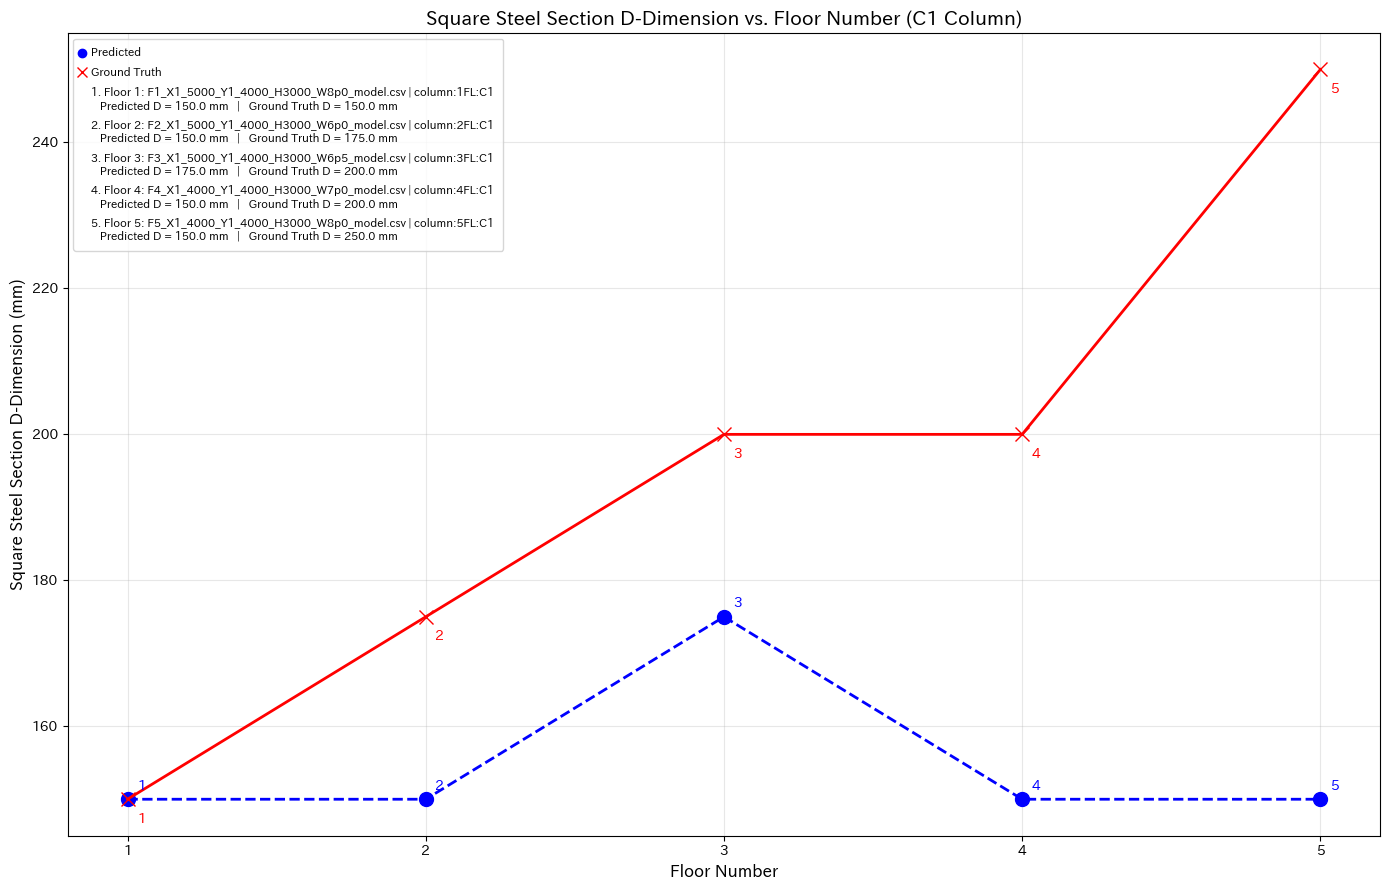

In [22]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ============================================================
# 1. Load CSV
# ============================================================

# Adjust the path below to match where your file is located.
# file_path = '/content/drive/My Drive/research/DNN6/dnn_result/test_catalog_predictions_lagrangian.csv'
# df = pd.read_csv(file_path)


# ============================================================
# 2. Extract floor number from slot
# ============================================================

def extract_floor(slot):
    """
    Extract the floor number from a column slot.

    Examples:
        column:1FL:C1 -> 1
        column:2FL:C1 -> 2
        column:3FL:C1 -> 3
        column:5FL:C1 -> 5
    """

    match = re.search(
        r'column:(\d+)FL:C1$',
        str(slot)
    )

    if match is None:
        return pd.NA

    return int(match.group(1))


df['floor'] = df['slot'].apply(
    extract_floor
)


# ============================================================
# 3. Select square steel sections for C1 columns
# ============================================================

# The dataframe uses:
#
#     section_type = 'box'
#
# for square steel sections.
#
# The C1 column slots are:
#
#     column:1FL:C1
#     column:2FL:C1
#     column:3FL:C1
#     ...
#
# Therefore, select only box sections whose slot corresponds
# to a C1 column.

df_box_c1 = df[
    (df['section_type'] == 'box') &
    (df['slot'].str.match(
        r'^column:\d+FL:C1$',
        na=False
    ))
].copy()


# ============================================================
# 4. Remove rows with missing required values
# ============================================================

df_box_c1 = df_box_c1.dropna(
    subset=[
        'floor',
        'pred_D',
        'true_D',
        'file_name',
        'slot'
    ]
)


# ============================================================
# 5. Convert floor number to integer
# ============================================================

df_box_c1['floor'] = (
    df_box_c1['floor']
    .astype(int)
)


# ============================================================
# 6. Select ONE C1 component for each floor
# ============================================================

# Sort first to make the selection deterministic.

df_box_c1 = df_box_c1.sort_values(
    ['floor', 'file_name', 'slot']
)


# Keep exactly one C1 component for each floor.

summary = (
    df_box_c1
    .drop_duplicates(
        subset='floor',
        keep='first'
    )
    .sort_values('floor')
    .reset_index(drop=True)
)


# ============================================================
# 7. Check that data exist
# ============================================================

if summary.empty:
    raise ValueError(
        'No valid C1 square steel column data were found '
        'in the CSV file.'
    )


# ============================================================
# 8. Generate graph
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 9)
)


# ============================================================
# 9. Plot predicted D-dimension
# ============================================================

ax.plot(
    summary['floor'],
    summary['pred_D'],
    marker='o',
    linestyle='--',
    color='blue',
    linewidth=2,
    markersize=10,
    label='Predicted'
)


# ============================================================
# 10. Plot ground-truth D-dimension
# ============================================================

ax.plot(
    summary['floor'],
    summary['true_D'],
    marker='x',
    linestyle='-',
    color='red',
    linewidth=2,
    markersize=10,
    label='Ground Truth'
)


# ============================================================
# 11. Add numbers to the plotted points
# ============================================================

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    # --------------------------------------------------------
    # Number next to predicted point
    # --------------------------------------------------------

    ax.annotate(
        str(i),
        xy=(
            row['floor'],
            row['pred_D']
        ),
        xytext=(7, 7),
        textcoords='offset points',
        color='blue',
        fontsize=10,
        fontweight='bold'
    )

    # --------------------------------------------------------
    # Number next to ground-truth point
    # --------------------------------------------------------

    ax.annotate(
        str(i),
        xy=(
            row['floor'],
            row['true_D']
        ),
        xytext=(7, -17),
        textcoords='offset points',
        color='red',
        fontsize=10,
        fontweight='bold'
    )


# ============================================================
# 12. Create custom legend
# ============================================================

# ------------------------------------------------------------
# First: explain the two plotted line types
# ------------------------------------------------------------

legend_handles = [
    Line2D(
        [0],
        [0],
        color='blue',
        linestyle='--',
        marker='o',
        linewidth=1.5,
        markersize=6,
        label='Predicted'
    ),

    Line2D(
        [0],
        [0],
        color='red',
        linestyle='-',
        marker='x',
        linewidth=1.5,
        markersize=7,
        label='Ground Truth'
    )
]


# ------------------------------------------------------------
# Second: add one legend entry for each numbered floor
# ------------------------------------------------------------

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    legend_text = (
        f'{i}. Floor {row["floor"]}: {component_name}\n'
        f'   Predicted D = {row["pred_D"]} mm'
        f'   |   Ground Truth D = {row["true_D"]} mm'
    )

    # Invisible handle.
    #
    # The number is included directly in the legend text.
    legend_handles.append(
        Line2D(
            [0],
            [0],
            color='none',
            linestyle='None',
            marker=None,
            label=legend_text
        )
    )


# ------------------------------------------------------------
# Display custom legend
# ------------------------------------------------------------

ax.legend(
    handles=legend_handles,
    loc='best',
    fontsize=8,
    frameon=True,
    handlelength=0,
    borderpad=0.8,
    labelspacing=0.8
)


# ============================================================
# 13. Axis labels
# ============================================================

ax.set_xlabel(
    'Floor Number',
    fontsize=12
)

ax.set_ylabel(
    'Square Steel Section D-Dimension (mm)',
    fontsize=12
)


# ============================================================
# 14. Title
# ============================================================

ax.set_title(
    'Square Steel Section D-Dimension vs. Floor Number '
    '(C1 Column)',
    fontsize=14
)


# ============================================================
# 15. Set x-axis ticks
# ============================================================

ax.set_xticks(
    summary['floor']
)


# ============================================================
# 16. Grid
# ============================================================

ax.grid(
    True,
    alpha=0.3
)


# ============================================================
# 17. Adjust layout
# ============================================================

plt.tight_layout()


# ============================================================
# 18. Save graph
# ============================================================

save_dir = OUTPUT_DIR

os.makedirs(
    save_dir,
    exist_ok=True
)

output_path = os.path.join(
    save_dir,
    'Square_Steel_D_Dimension_vs_Floor_C1.png'
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches='tight'
)


# ============================================================
# 19. Download graph
# ============================================================

files.download(
    output_path
)


# ============================================================
# 20. Output plotted components to terminal
# ============================================================

print(
    f'Saved graph to: {output_path}'
)

print('\nC1 square steel components plotted:')
print('=' * 120)

for i, (_, row) in enumerate(
    summary.iterrows(),
    start=1
):

    component_name = (
        f'{row["file_name"]} | {row["slot"]}'
    )

    print(
        f'[{i}] Floor: {row["floor"]}'
    )

    print(
        f'    Component: {component_name}'
    )

    print(
        f'    Predicted D:    {row["pred_D"]} mm'
    )

    print(
        f'    Ground Truth D: {row["true_D"]} mm'
    )

    print('-' * 120)


print(
    f'Total number of floors plotted: '
    f'{summary["floor"].nunique()}'
)


# ============================================================
# 21. Display graph
# ============================================================

plt.show()

## Model visualization

In [ ]:
!pip install torchinfo

In [ ]:
from torchinfo import summary


summary(model, input_size=(1, len(FEATURE_NORMALIZATION)))

Layer (type:depth-idx)                   Output Shape              Param #
SimpleDNN                                [1, 15, 23]               --
├─Sequential: 1-1                        [1, 128]                  --
│    └─Linear: 2-1                       [1, 128]                  8,704
│    └─ReLU: 2-2                         [1, 128]                  --
│    └─Linear: 2-3                       [1, 128]                  16,512
│    └─ReLU: 2-4                         [1, 128]                  --
├─Linear: 1-2                            [1, 345]                  44,505
├─Linear: 1-3                            [1, 290]                  37,410
Total params: 107,131
Trainable params: 107,131
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.11
Input size (MB): 0.00
Forward/backward pass size (MB): 0.01
Params size (MB): 0.43
Estimated Total Size (MB): 0.44

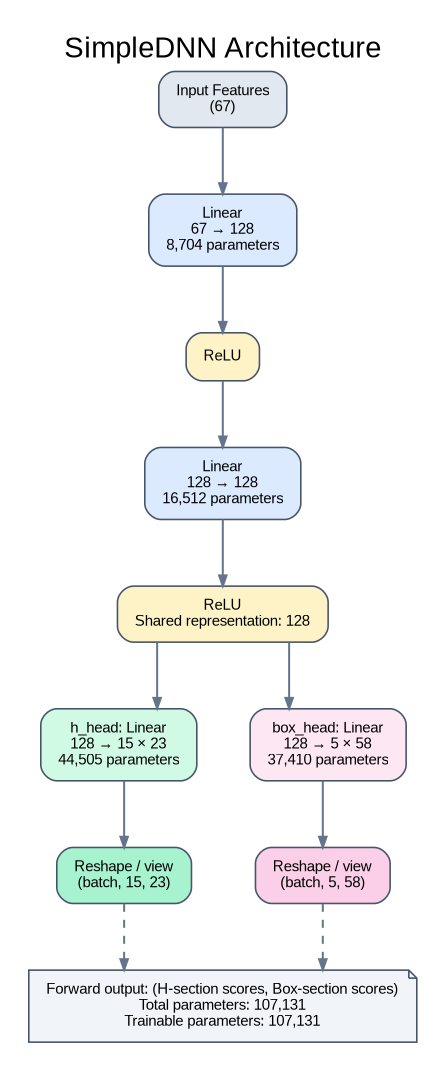

Saved diagram: /content/SimpleDNN_architecture.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

!apt-get -qq install -y graphviz
!pip -q install graphviz

from graphviz import Digraph
from IPython.display import display, Image
from google.colab import files





_nf = len(FEATURE_NORMALIZATION)
_h_out = N_H_SLOTS * len(H_CATALOG); _box_out = N_BOX_SLOTS * len(BOX_CATALOG)
_total_params = sum(p.numel() for p in model.parameters())
_trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

dot = Digraph("SimpleDNN", format="png", engine="dot")

dot.attr(
    rankdir="TB",
    bgcolor="white",
    pad="0.3",
    nodesep="0.55",
    ranksep="0.7",
    splines="ortho",
    label="SimpleDNN Architecture",
    labelloc="t",
    fontsize="22",
    fontname="Arial"
)

dot.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Arial",
    fontsize="11",
    margin="0.18,0.12",
    color="#475569",
    penwidth="1.2"
)

dot.attr(
    "edge",
    color="#64748b",
    penwidth="1.5",
    arrowsize="0.8"
)

# ------------------------------------------------------------

# ------------------------------------------------------------
dot.node(
    "input",
    f"Input Features\n({_nf})",
    fillcolor="#E2E8F0"
)

# ------------------------------------------------------------

# ------------------------------------------------------------
dot.node(
    "fc1",
    f"Linear\n{_nf} → 128\n{_nf*128+128:,} parameters",
    fillcolor="#DBEAFE"
)

dot.node(
    "relu1",
    "ReLU",
    fillcolor="#FEF3C7"
)

dot.node(
    "fc2",
    "Linear\n128 → 128\n16,512 parameters",
    fillcolor="#DBEAFE"
)

dot.node(
    "relu2",
    "ReLU\nShared representation: 128",
    fillcolor="#FEF3C7"
)

dot.edge("input", "fc1")
dot.edge("fc1", "relu1")
dot.edge("relu1", "fc2")
dot.edge("fc2", "relu2")

# ------------------------------------------------------------

# ------------------------------------------------------------
dot.node(
    "h_head",
    f"h_head: Linear\n128 → {N_H_SLOTS} × {len(H_CATALOG)}\n{128*_h_out+_h_out:,} parameters",
    fillcolor="#D1FAE5"
)

dot.node(
    "h_view",
    f"Reshape / view\n(batch, {N_H_SLOTS}, {len(H_CATALOG)})",
    fillcolor="#A7F3D0"
)

# ------------------------------------------------------------

# ------------------------------------------------------------
dot.node(
    "box_head",
    f"box_head: Linear\n128 → {N_BOX_SLOTS} × {len(BOX_CATALOG)}\n{128*_box_out+_box_out:,} parameters",
    fillcolor="#FCE7F3"
)

dot.node(
    "box_view",
    f"Reshape / view\n(batch, {N_BOX_SLOTS}, {len(BOX_CATALOG)})",
    fillcolor="#FBCFE8"
)


dot.edge("relu2", "h_head")
dot.edge("h_head", "h_view")

dot.edge("relu2", "box_head")
dot.edge("box_head", "box_view")


with dot.subgraph() as s:
    s.attr(rank="same")
    s.node("h_head")
    s.node("box_head")

with dot.subgraph() as s:
    s.attr(rank="same")
    s.node("h_view")
    s.node("box_view")

# ------------------------------------------------------------

# ------------------------------------------------------------
dot.node(
    "output",
    "Forward output: (H-section scores, Box-section scores)\n"
    f"Total parameters: {_total_params:,}\n"
    f"Trainable parameters: {_trainable_params:,}",
    shape="note",
    fillcolor="#F1F5F9"
)

dot.edge("h_view", "output", style="dashed")
dot.edge("box_view", "output", style="dashed")

# ------------------------------------------------------------

# ------------------------------------------------------------
output_path = "/content/SimpleDNN_architecture"
dot.render(output_path, cleanup=True)

display(Image(filename=output_path + ".png"))

print(f"Saved diagram: {output_path}.png")


files.download(output_path + ".png")


## Supplementary analysis